# AccessBay: How Accessible Are the Bay Area's Essential Places?
**Question:** Can Bay Area residents with disabilities reach and use the places they need, and does it depend on where they live?

**Data:** Google Maps Places, Google Maps Reviews, Census ACS S1810, Census TIGER tracts, transit GTFS feeds, OpenStreetMap.

**Notebook outline**
1. Setup
2. Load and clean Places
3. Parse accessibility tags and physical score
4. Transit access (GTFS)
5. Census need vs. supply
6. Final score and website export
7. Validation: Street View spot check
8. Reviews: lived experience
9. Recreation (OpenStreetMap)
10. Limitations and Ethics
11. Conclusion and Recommendations

## 1. Setup
Mount Google Drive, install extra packages, import libraries and set file paths.

In [2]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [3]:
!pip install -q geopandas osmnx

In [4]:
import os, json, re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

In [5]:
for root, dirs, files in os.walk("/content/drive/MyDrive", followlinks=True):
    for f in files:
        if f.endswith(".csv"):
            print(os.path.join(root, f))

/content/drive/MyDrive/google maps dataset/google_maps.csv
/content/drive/MyDrive/google maps dataset/Google maps reviews_sample.csv
/content/drive/MyDrive/google maps reviews dataset/google_maps_reviews.csv
/content/drive/MyDrive/reddit_dataset/reddit_posts.csv
/content/drive/MyDrive/reddit_dataset/Reddit Posts_sample.csv
/content/drive/MyDrive/zillow housing dataset/Zillow properties listing information_sample.csv
/content/drive/MyDrive/zillow housing dataset/Zillow_part1.csv
/content/drive/MyDrive/zillow housing dataset/zillow_part3.csv
/content/drive/MyDrive/zillow housing dataset/zillow_part2.csv
/content/drive/MyDrive/AccessBay/processed/places_app.csv
/content/drive/MyDrive/AccessBay/processed/streetview_check_filled.csv
/content/drive/MyDrive/AccessBay/processed/streetview_check.csv
/content/drive/MyDrive/AccessBay/processed/streetview_check_blank.csv


In [6]:
PLACES_PATH  = "/content/drive/MyDrive/google maps dataset/google_maps.csv"
REVIEWS_PATH = "/content/drive/MyDrive/google maps reviews dataset/google_maps_reviews.csv"

PROJECT   = "/content/drive/MyDrive/AccessBay"
PROCESSED = f"{PROJECT}/processed"
EXTERNAL  = f"{PROJECT}/external"
os.makedirs(PROCESSED, exist_ok=True)
os.makedirs(EXTERNAL, exist_ok=True)

## 2. Load and clean Places
Steps: drop duplicate place IDs, remove permanently closed places, spot-check categories.

In [7]:
places_raw = pd.read_csv(PLACES_PATH)
print("Rows:", len(places_raw))
print("Unique place_ids:", places_raw["place_id"].nunique())
places_raw.head(3)

Rows: 147429
Unique place_ids: 147429


,place_id,url,country,name,category,address,description,business_details,open_hours,reviews_count,rating,main_image,reviews,lat,lon,services_provided,hotel_amenities,hotel_star_ratings,open_website,phone_number,permanently_closed,photos_and_videos,people_also_search,web_results,reservation_link,questions_answers,top_reviews,reviews_snippets,directory_categories,directory_locations,popular_times,cid_location,is_claimed,fid_location,review_distribution,all_categories,country_code,cid,temporarily_closed,category_index,about
0,ChIJvzRthJuwj4ARIHqv4q88zIA,https://www.google.com/maps/place/?q=place_id%3AChIJvzRthJuwj4ARIHqv4q88zIA&hl=en,United States,"Dr. Vidushi Savant, MD ( Psychiatrist )",Psychiatrist,"4546 El Camino Real B10-740, Los Altos, CA 94022, United States",NaN,"[{""details"":""4546 El Camino Real B10-740, Los Altos, CA 94022, United States "",""field_name"":""address"",""link"":null},{...","{""Friday"":""12 am–5 pm\n8 pm–12 am"",""Monday"":""8 pm–12 am"",""Saturday"":""12 am–5 pm"",""Sunday"":""Closed"",""Thursday"":""12 am...",0.0,0.0,https://lh3.googleusercontent.com/grass-cs/AABkmLeu-T_nsFGihE5UO-U2juPCfvoWBzKWfprhK-Ihz-bVha6YIdpB4woPyiAPq9DFBFx4t...,NaN,37.400890,-122.114580,"[""Wheelchair-accessible car park"",""Wheelchair-accessible entrance"",""Wheelchair-accessible seating"",""Wheelchair-acces...",NaN,NaN,https://www.integrativebehavioral.com/,+1 650-770-1401,False,"[""https://streetviewpixels-pa.googleapis.com/v1/thumbnail?panoid=WrHn2lrNsHC6UWDJ4axckQ&cb_client=maps_sv.tactile.gp...","[{""category"":""Doctor"",""name"":""Vidushi Savant"",""rating"":0,""reviews_num"":0,""url"":""https://www.google.com/maps?cid=1063...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-9165884415485707744,True,0x808fb09b846d34bf:0x80cc3cafe2af7a20,"{""1_star_reviews"":null,""2_star_reviews"":null,""3_star_reviews"":null,""4_star_reviews"":null,""5_star_reviews"":null}","[""Psychiatrist"",""Mental Hospital"",""Mental health service"",""Psychosomatic medical practitioner""]",US,9280859658223843872,False,"{""gcid"":""gcid:psychiatrist"",""gcid_clean"":""Psychiatrist"",""kg_entity_id"":null}",NaN
1,ChIJpcw_ho17j4ARZbq4B37shiw,https://www.google.com/maps/place/Target%20Optical/data=!4m7!3m6!1s0x808f7b8d863fcca5:0x2c86ec7e07b8ba65!8m2!3d37.67...,United States,Target Optical,Optometrist,"133 Serramonte Center, Daly City, CA 94015, United States",NaN,"[{""details"":""133 Serramonte Center, Daly City, CA 94015, United States "",""field_name"":""address"",""link"":null},{""detai...","{""Friday"":""9 AM–7 PM"",""Monday"":""9 AM–7 PM"",""Saturday"":""9 AM–6 PM"",""Sunday"":""12–4 PM"",""Thursday"":""9 AM–7 PM"",""Tuesday...",468.0,4.8,https://lh3.googleusercontent.com/grass-cs/AABkmLf1yBOkwKRB_kYSxD0wzW_Ulf4v1OKUGC_pQzbWj24V_re86sPaeGBDmCNFXkTniqiM7...,NaN,37.670495,-122.470837,"[""Wheelchair-accessible car park"",""Wheelchair-accessible entrance""]",NaN,NaN,https://local.targetoptical.com/ca/daly-city/133-serramonte-center.html?cid=yext_4962&y_source=1_MTIxODAxNS03MTUtbG9...,+1 650-756-6684,False,"[""https://streetviewpixels-pa.googleapis.com/v1/thumbnail?panoid=ud1h8lSyr0L5ZS2VTyCFZw&cb_client=search.gws-prod.gr...",NaN,NaN,https://exams.eyeappts.com/googlereserve/ScheduleExam?modal=true&StoreNumber=TG000004962&rwg_token=ALcMQYbad6mZBo1su...,NaN,"[{""content"":""I purchased my second pair of eyeglasses today. When I bought my first pair, I wasn't able to get a sec...","[{""content"":""\""Always excellent service and great selection at great prices.\"""",""reviewer_image_url"":""https://lh3.go...",NaN,NaN,NaN,3208511810587638373,True,0x808f7b8d863fcca5:0x2c86ec7e07b8ba65,"{""1_star_reviews"":15,""2_star_reviews"":2,""3_star_reviews"":2,""4_star_reviews"":3,""5_star_reviews"":446}","[""Optometrist"",""Sunglasses store""]",US,3208511810587638373,False,"{""gcid"":""gcid:optometrist"",""gcid_clean"":""Optometrist"",""kg_entity_id"":""/g/1vsprr0b""}",NaN
2,ChIJ82bdCgYphYARU07Oaub8ras,"https://www.google.com/maps/place/Division%2FRheumatology+Allergy/@38.5339853

In [8]:
places = places_raw.drop_duplicates("place_id").copy()
places = places[places["permanently_closed"] != True]
print("After dedupe + closed filter:", len(places))

places["category"].value_counts().head(40)

After dedupe + closed filter: 135262


,count
category,
Bus stop,18261
Doctor,11251
Dentist,8410
Medical clinic,5013
Internist,4787
Psychologist,4567
Non-profit organization,4212
Psychotherapist,3515
Transport hub,3429


**Cleaning notes:** 147k rows, not 100k. The same feature has several spellings. Some tags are negative. Some categories are off-topic.

## 3. Parse accessibility tags
`services_provided` holds Google's listed attributes (e.g. "Wheelchair-accessible entrance"). We turn these into yes/no columns.
A place with **no** attributes at all is marked *Unknown*, not inaccessible.

In [9]:
def parse_list(x):
    try:
        val = json.loads(x) if isinstance(x, str) else []
        return val if isinstance(val, list) else []
    except Exception:
        return []

places["tags"] = places["services_provided"].apply(parse_list)

tag_counts = Counter(t for tags in places["tags"] for t in tags)
access_words = ["accessib", "wheelchair", "hearing", "braille", "sign language", "lift", "elevator", "assistive"]
access_tags = {t: n for t, n in tag_counts.items() if any(w in t.lower() for w in access_words)}

for t, n in sorted(access_tags.items(), key=lambda x: -x[1]):
    print(f"{n:>7}  {t}")

  87132  Wheelchair-accessible entrance
  82212  Wheelchair-accessible car park
  54106  Wheelchair-accessible toilet
  12193  Wheelchair accessible entrance
   9393  Wheelchair accessible parking lot
   6248  Wheelchair accessible restroom
   2281  Wheelchair-accessible seating
   1846  Wheelchair-accessible parking lot
   1143  Wheelchair-accessible washroom
    594   Does not have assistive hearing loop
    536  No wheelchair-accessible entrance
    498  No wheelchair-accessible seating
    468  No wheelchair-accessible toilet
    325  Wheelchair accessible seating
    307  No wheelchair-accessible car park
     83  No wheelchair accessible seating
     77  Assistive hearing loop
     62  No wheelchair accessible entrance
     58  No wheelchair accessible restroom
     31  No wheelchair accessible parking lot
     15  No wheelchair-accessible washroom
      7  No wheelchair-accessible parking lot


In [10]:
for t in access_tags:
    places[t] = places["tags"].apply(lambda tags, t=t: t in tags)

places["n_access_tags"]   = places[list(access_tags)].sum(axis=1)
places["has_any_tags"]    = places["tags"].apply(len) > 0
places["has_access_info"] = places["n_access_tags"] > 0

print("Share with ANY listed attributes:", round(places["has_any_tags"].mean(), 3))
print("Share with ANY accessibility attribute:", round(places["has_access_info"].mean(), 3))

Share with ANY listed attributes: 0.885
Share with ANY accessibility attribute: 0.795


In [11]:
places.to_pickle(f"{PROCESSED}/places_tagged.pkl")
print("Saved.")

Saved.


### 3b. Clean accessibility features
Google lists the same feature under different wording ("toilet" / "restroom" / "washroom", "car park" / "parking lot") and also records explicit negatives ("No wheelchair-accessible entrance"). We collapse these into one column per feature, each with three states: **yes / no / unknown**.

In [12]:
FEATURES = {
    "entrance":     r"entrance",
    "parking":      r"car park|parking",
    "toilet":       r"toilet|restroom|washroom",
    "seating":      r"seating",
    "hearing_loop": r"hearing loop",
}

def feature_status(tags):
    out = {f: "unknown" for f in FEATURES}
    for tag in tags:
        t = tag.lower().strip()
        if not ("wheelchair" in t or "hearing loop" in t):
            continue
        is_neg = t.startswith("no ") or t.startswith("does not")
        for f, pattern in FEATURES.items():
            if re.search(pattern, t):
                if is_neg:
                    out[f] = "no"                 # an explicit "no" wins
                elif out[f] != "no":
                    out[f] = "yes"
    return out

status = places["tags"].apply(feature_status).apply(pd.Series)
places = pd.concat([places.drop(columns=list(FEATURES), errors="ignore"), status], axis=1)

for f in FEATURES:
    print(f"\n{f}"); print(places[f].value_counts())


entrance
entrance
yes        99325
unknown    35339
no           598
Name: count, dtype: int64

parking
parking
yes        93451
unknown    41466
no           345
Name: count, dtype: int64

toilet
toilet
unknown    73224
yes        61497
no           541
Name: count, dtype: int64

seating
seating
unknown    132075
yes          2606
no            581
Name: count, dtype: int64

hearing_loop
hearing_loop
unknown    134591
no            594
yes            77
Name: count, dtype: int64


In [13]:
sample = places.sample(10, random_state=42)[["name", "services_provided"] + list(FEATURES)]
sample

,name,services_provided,entrance,parking,toilet,seating,hearing_loop
23604,Rise Economy,"[""Wheelchair-accessible car park"",""Wheelchair-accessible entrance""]",yes,yes,unknown,unknown,unknown
75012,Allen Dr & Ross Way,NaN,unknown,unknown,unknown,unknown,unknown
100565,United States Postal Service,"[""Wheelchair-accessible car park"",""Wheelchair-accessible entrance""]",yes,yes,unknown,unknown,unknown
56156,Dung Cai,"[""Toilet""]",unknown,unknown,unknown,unknown,unknown
116928,Laundry Time Laundromat,"[""Wheelchair-accessible car park"",""Wheelchair-accessible entrance""]",yes,yes,unknown,unknown,unknown
120161,Kaiser Medical Center,"[""Passenger loading area"",""Wheelchair-accessible toilet""]",unknown,unknown,yes,unknown,unknown
122260,"Abid Qureshi, MD","[""Wheelchair-accessible car park"",""Wheelchair-accessible entrance"",""Wheelchair-accessible seating"",""Wheelchair-acces...",yes,yes,yes,yes,unknown
99294,"Rima Lieben, MD","[""Wheelchair-accessible car park"",""Wheelchair-accessible entrance"",""Wheelchair-accessible toilet""]",yes,yes,yes,unknown,unknown
20554,Selah Garden Counseling,"[""Wheelchair-accessible car park"",""Wheelchair-accessible entrance"",""Wheelchair-accessible toilet"",""Toilet"",""Appointm...",yes,yes,yes,unknown,unknown
33632,"Chelsie Crilly, LMFT","[""Identifies as LGBTQ+ owned"",""On-site services"",""Wheelchair-accessible car park"",""Gender-neutral toilets"",""Toilet"",...",unknown,yes,unknown,unknown,unknown


**Hand check:** Reviewed 10 random places; parsed features matched the raw tags in 8/10.

### 3c. Group categories
Keep only essential services and recreation. Off-topic categories (e.g. martial arts schools, fire stations) are dropped.

In [14]:
GROUPS = [
    ("Pharmacy",       r"pharmac|drugstore"),
    ("Mental health",  r"psycholog|psychiatr|psychotherap|mental health|counselor|addiction|"
                       r"rehabilitation center|treatment center"),
    ("Health care",    r"doctor|clinic|hospital|physician|internist|pediatric|dentist|optometrist|"
                       r"surgeon|cardiolog|podiatr|obstetric|gynecolog|urgent care|emergency|"
                       r"physical therap|medical|oncolog|health center|eye care"),
    ("Food",           r"grocery|supermarket|food bank|food pantry|produce market|convenience store"),
    ("Financial",      r"\bbank\b|credit union|check cashing|money transfer"),
    ("Gov & social services", r"government office|social services|post office|library|shelter|"
                       r"non-profit|community center|employment agency|motor vehicles|"
                       r"police|school district office"),
    ("Education & child care", r"preschool|pre-school|day care|child care|elementary school|middle school|"
                           r"high school|primary school|nursery school|charter school|catholic school|"
                           r"special education|college|adult education|montessori|after school|"
                           r"general education school"),
    ("Transit",        r"bus stop|transport hub|train station|transit station"),
    ("Recreation",     r"\bpark\b|playground|beach|trail"),
]
EXCLUDE = r"martial arts|dance school|driving school|music school|art school|language school|" \
          r"sports school|swimming school|riding school|fire station|parking"

def assign_group(cat):
    c = str(cat).lower()
    if re.search(EXCLUDE, c):
        return "Other"
    for name, pattern in GROUPS:
        if re.search(pattern, c):
            return name
    return "Other"

places["group"] = places["category"].apply(assign_group)
print(places["group"].value_counts())
print("\nTop categories landing in 'Other' (check nothing important is lost):")
print(places.loc[places["group"] == "Other", "category"].value_counts().head(25))

group
Health care               56326
Transit                   21845
Mental health             18780
Gov & social services     11597
Education & child care     9591
Other                      6580
Food                       4370
Financial                  3678
Recreation                 1324
Pharmacy                   1171
Name: count, dtype: int64

Top categories landing in 'Other' (check nothing important is lost):
category
Martial arts school         795
Dance school                774
Fire station                771
Laundromat                  700
Music school                503
Driving school              321
Art school                  287
Language school             149
Sports school               108
Swimming school             104
Horse riding school          97
Flight school                89
Trade school                 85
Computer training school     82
Ballet school                80
Beauty school                60
Nursing school               57
Vocational school        

### 3d. Category-aware physical score
A restroom is only expected at some kinds of places. Toilet accessibility counts only for health care, mental health, government/social services and education. Other places are scored on entrance and parking.
Score = 5 × (weight of confirmed features ÷ weight of applicable features).
Transit stops are excluded here and handled with GTFS in Part 4.

In [15]:
WEIGHTS = {"entrance": 2.5, "toilet": 1.5, "parking": 1.0}
TOILET_GROUPS = {"Health care", "Mental health", "Gov & social services"}

LABELS = {"entrance": "entrance", "toilet": "toilet", "parking": "parking",
          "seating": "seating", "hearing_loop": "assistive hearing loop"}

def applicable(group):
    return ["entrance", "toilet", "parking"] if group in TOILET_GROUPS else ["entrance", "parking"]

def physical_score(row):
    feats = applicable(row["group"])
    if all(row[f] == "unknown" for f in feats):
        return np.nan
    got = sum(WEIGHTS[f] for f in feats if row[f] == "yes")
    return round(5 * got / sum(WEIGHTS[f] for f in feats), 2)

def confidence(row):
    feats = applicable(row["group"])
    n = sum(row[f] != "unknown" for f in feats)
    return "Confirmed" if n == len(feats) else ("Partial" if n > 0 else "Unknown")

def reasons(row):
    out = []
    for f in ["entrance", "toilet", "parking", "seating", "hearing_loop"]:
        if f == "toilet" and row["group"] not in TOILET_GROUPS and row[f] == "unknown":
            continue
        if row[f] == "yes":
            out.append("✓ Assistive hearing loop" if f == "hearing_loop" else f"✓ Wheelchair-accessible {LABELS[f]}")
        elif row[f] == "no":
            out.append(f"✗ No accessible {LABELS[f]}")
        elif f in WEIGHTS:
            out.append(f"? {LABELS[f].capitalize()} accessibility not listed")
    return out

scored = places[~places["group"].isin(["Other", "Transit"])].copy()
scored["physical_score"] = scored.apply(physical_score, axis=1)
scored["confidence"]     = scored.apply(confidence, axis=1)
scored["reasons"]        = scored.apply(reasons, axis=1)

print(len(scored), "places scored")
print(scored["confidence"].value_counts(normalize=True).round(3))
print(scored.groupby("group")["confidence"].value_counts(normalize=True).unstack().round(2))
print(scored.groupby("group")["physical_score"].mean().round(2).sort_values())

106837 places scored
confidence
Confirmed    0.635
Partial      0.279
Unknown      0.087
Name: proportion, dtype: float64
confidence              Confirmed  Partial  Unknown
group                                              
Education & child care       0.64     0.19     0.16
Financial                    0.81     0.16     0.03
Food                         0.78     0.15     0.07
Gov & social services        0.19     0.72     0.09
Health care                  0.82     0.15     0.04
Mental health                0.26     0.52     0.22
Pharmacy                     0.89     0.06     0.05
Recreation                   0.80     0.18     0.02
group
Mental health             3.37
Gov & social services     3.58
Education & child care    4.26
Financial                 4.62
Food                      4.69
Recreation                4.73
Health care               4.75
Pharmacy                  4.76
Name: physical_score, dtype: float64


**Cleaning Notes:** toilet only scored where a public restroom is expected; Education removed after review.

In [16]:
scored.to_pickle(f"{PROCESSED}/places_scored_physical.pkl")
places[places["group"] == "Transit"].to_pickle(f"{PROCESSED}/google_transit_stops.pkl")
print("Saved.")

Saved.


**Finding 1:**
Mental health is the clear outlier. 22% unknown and only 26% confirmed,
compared with 4% and 82% for general health care. Its average score is 3.37 vs. 4.75.

Government and social services score low too (3.58). These are places people often have to visit, like the DMV and benefits offices, and they’re among the least documented.

## 4. Transit access (GTFS)
Source: 511.org regional GTFS feed (all Bay Area agencies). `stops.txt` includes `wheelchair_boarding` (0/blank = unknown, 1 = accessible, 2 = not accessible).
For each place we compute:
- distance to the nearest wheelchair-accessible stop → transit points (0 to 3)
- whether it is within 3/4 mile of any fixed-route stop → ADA paratransit zone (0 or 1)

In [17]:
import requests, zipfile, io
from google.colab import userdata

CENSUS_KEY = userdata.get("CENSUS_KEY").strip()
API_KEY    = userdata.get("API_511").strip()

url = f"https://api.511.org/transit/datafeeds?api_key={API_KEY}&operator_id=RG"
r = requests.get(url, timeout=300)
print("Status:", r.status_code, "| size:", round(len(r.content) / 1e6, 1), "MB")

if r.status_code != 200:
    print("Server said:", r.text[:300])
else:
    gtfs_dir = f"{EXTERNAL}/gtfs_regional"
    zipfile.ZipFile(io.BytesIO(r.content)).extractall(gtfs_dir)
    print(os.listdir(gtfs_dir))

Status: 200 | size: 59.8 MB
['shapes.txt', 'stop_times.txt', 'areas.txt', 'calendar_dates.txt', 'calendar.txt', 'calendar_attributes.txt', 'directions.txt', 'changes-toc.md', 'attributions.txt', 'agency.txt', 'fare_leg_join_rules.txt', 'pathways.txt', 'rider_categories.txt', 'mtc_feed_versions.txt', 'fare_products.txt', 'levels.txt', 'fare_leg_rules.txt', 'fare_transfer_rules.txt', 'feed_info.txt', 'fare_media.txt', 'route_attributes.txt', 'routes.txt', 'stop_areas.txt', 'timeframes.txt', 'transfers.txt', 'stops.txt', 'trips.txt']


In [18]:
stops = pd.read_csv(f"{gtfs_dir}/stops.txt", dtype=str)
stops["stop_lat"] = stops["stop_lat"].astype(float)
stops["stop_lon"] = stops["stop_lon"].astype(float)

# Child stops inherit wheelchair_boarding from their parent station when blank
if "parent_station" in stops.columns and "wheelchair_boarding" in stops.columns:
    parent_wb = stops.set_index("stop_id")["wheelchair_boarding"]
    blank = stops["wheelchair_boarding"].isin([None, "", "0"]) | stops["wheelchair_boarding"].isna()
    stops.loc[blank, "wheelchair_boarding"] = stops.loc[blank, "parent_station"].map(parent_wb)

stops["wheelchair_boarding"] = stops["wheelchair_boarding"].fillna("0").replace("", "0")
print(len(stops), "stops")
print(stops["wheelchair_boarding"].value_counts(normalize=True).round(3))

21659 stops
wheelchair_boarding
0    0.681
1    0.254
2    0.064
Name: proportion, dtype: float64


In [19]:
from sklearn.neighbors import BallTree

R = 6_371_000  # Earth radius in meters

def to_rad(lat, lon):
    return np.deg2rad(np.c_[lat, lon])

# Keep real stops and stations (drop entrances, generic nodes, boarding areas)
if "location_type" in stops.columns:
    stops["location_type"] = stops["location_type"].fillna("0").replace("", "0")
    stops = stops[stops["location_type"].isin(["0", "1"])]

usable    = stops[stops["wheelchair_boarding"] != "2"]   # accessible or unknown
confirmed = stops[stops["wheelchair_boarding"] == "1"]   # explicitly accessible

place_pts = to_rad(scored["lat"].values, scored["lon"].values)

def nearest_m(df):
    tree = BallTree(to_rad(df["stop_lat"].values, df["stop_lon"].values), metric="haversine")
    d, _ = tree.query(place_pts, k=1)
    return (d[:, 0] * R).round(0)

scored["dist_usable_stop_m"]    = nearest_m(usable)
scored["dist_confirmed_stop_m"] = nearest_m(confirmed)
scored["dist_any_stop_m"]       = nearest_m(stops)

def transit_points(d):
    if d <= 400:  return 3   # ~5 min walk / roll
    if d <= 800:  return 2
    if d <= 1600: return 1
    return 0

scored["transit_score"]  = scored["dist_usable_stop_m"].apply(transit_points)
scored["in_paratransit"] = scored["dist_any_stop_m"] <= 1207   # 3/4 mile
scored["paratransit_pt"] = scored["in_paratransit"].astype(int)

print(len(usable), "usable stops |", len(confirmed), "confirmed accessible")
print(scored["transit_score"].value_counts().sort_index())
print("Outside ADA paratransit zone:", (~scored["in_paratransit"]).sum())
print(scored.groupby("group")[["transit_score", "dist_usable_stop_m"]].median().round(0))

19020 usable stops | 5023 confirmed accessible
transit_score
0     7919
1     3111
2     5946
3    89861
Name: count, dtype: int64
Outside ADA paratransit zone: 7493
                        transit_score  dist_usable_stop_m
group                                                    
Education & child care            3.0               217.0
Financial                         3.0               103.0
Food                              3.0               109.0
Gov & social services             3.0               149.0
Health care                       3.0               119.0
Mental health                     3.0               117.0
Pharmacy                          3.0               121.0
Recreation                        3.0               264.0


In [20]:
scored.to_pickle(f"{PROCESSED}/places_scored_transit.pkl")
print("Saved.")

Saved.


**Data decision:** 68% of regional GTFS stops have `wheelchair_boarding` unknown, 25% accessible, 6% not accessible. Because ADA requires accessible fixed-route vehicles, we treat unknown stops as usable and exclude only stops explicitly marked not accessible. The distance to the nearest *confirmed* accessible stop is kept separately and shown on the website.

## 5. Need vs. supply (Census)
Sources: ACS 2023 5-year table S1810 (disability by tract) and Census TIGER/Line 2023 tract boundaries.
Steps: download both, keep the 9 Bay Area counties, join every place to its tract, then compare where disabled residents live with where accessible essential services are.
Places outside the 9 counties (e.g. Davis, Santa Cruz) are dropped here, since our transit data does not cover them.

In [21]:
import geopandas as gpd

BAY_COUNTIES = {"001": "Alameda", "013": "Contra Costa", "041": "Marin", "055": "Napa",
                "075": "San Francisco", "081": "San Mateo", "085": "Santa Clara",
                "095": "Solano", "097": "Sonoma"}

# ACS disability by tract

resp = requests.get(
    "https://api.census.gov/data/2023/acs/acs5/subject",
        params=[
        ("get", "NAME,S1810_C01_001E,S1810_C02_001E,S1810_C03_001E"),
        ("for", "tract:*"),
        ("in", "state:06"),
        ("key", CENSUS_KEY),
    ],
    timeout=180,
)
print("Status:", resp.status_code)

try:
    rows = resp.json()
except Exception:
    print("Not JSON. Server said:\n", resp.text[:500])
    raise

acs = pd.DataFrame(rows[1:], columns=rows[0]).rename(columns={
    "S1810_C01_001E": "pop_total",
    "S1810_C02_001E": "pop_disabled",
    "S1810_C03_001E": "pct_disabled",
})
acs = acs[acs["county"].isin(BAY_COUNTIES)]
for c in ["pop_total", "pop_disabled", "pct_disabled"]:
    acs[c] = pd.to_numeric(acs[c], errors="coerce")
    acs.loc[acs[c] < 0, c] = np.nan
acs["GEOID"] = acs["state"] + acs["county"] + acs["tract"]
print(len(acs), "Bay Area tracts")
acs[["pop_total", "pop_disabled", "pct_disabled"]].describe().round(1)

Status: 200
1772 Bay Area tracts


,pop_total,pop_disabled,pct_disabled
count,1772.0,1772.0,1758.0
mean,4275.3,437.1,10.6
std,1647.9,233.9,5.1
min,0.0,0.0,0.0
25%,3154.8,274.8,7.3
50%,4129.0,405.0,9.9
75%,5290.2,548.0,12.7
max,12782.0,1813.0,54.2


In [22]:
tracts = gpd.read_file("https://www2.census.gov/geo/tiger/TIGER2023/TRACT/tl_2023_06_tract.zip")
tracts = tracts[tracts["COUNTYFP"].isin(BAY_COUNTIES)][["GEOID", "COUNTYFP", "geometry"]]
tracts["county"] = tracts["COUNTYFP"].map(BAY_COUNTIES)
tracts = tracts.merge(acs[["GEOID", "pop_total", "pop_disabled", "pct_disabled"]], on="GEOID", how="left")
print(len(tracts), "Bay Area tracts")

1772 Bay Area tracts


In [23]:
pts = gpd.GeoDataFrame(scored, geometry=gpd.points_from_xy(scored["lon"], scored["lat"]), crs="EPSG:4326")
pts = pts.to_crs(tracts.crs)
pts = gpd.sjoin(pts, tracts[["GEOID", "county", "geometry"]], how="inner", predicate="within")
pts = pts.drop(columns="index_right")

print(len(scored), "→", len(pts), "places inside the 9 counties")
print("Outside ADA paratransit zone (9 counties only):", (~pts["in_paratransit"]).sum())
print(pts.groupby("county")["in_paratransit"].apply(lambda s: (~s).sum()).sort_values(ascending=False))

106837 → 101101 places inside the 9 counties
Outside ADA paratransit zone (9 counties only): 2152
county
Solano           424
Santa Clara      409
Sonoma           288
Contra Costa     247
San Francisco    215
Napa             190
Marin            135
San Mateo        126
Alameda          118
Name: in_paratransit, dtype: int64


In [24]:
no_addr = pts["address"].isna()
print("Places with no address:", no_addr.sum())
print("Of those, by group:\n", pts.loc[no_addr, "group"].value_counts())

pts = pts[~no_addr].copy()
print("\nRemaining places:", len(pts))
print("Outside ADA paratransit zone (9 counties, with address):", (~pts["in_paratransit"]).sum())
print(pts.groupby("county")["in_paratransit"].apply(lambda s: (~s).sum()).sort_values(ascending=False))

Places with no address: 1088
Of those, by group:
 group
Gov & social services     349
Mental health             347
Education & child care    210
Health care               160
Food                       18
Pharmacy                    3
Financial                   1
Name: count, dtype: int64

Remaining places: 100013
Outside ADA paratransit zone (9 counties, with address): 1661
county
Solano           381
Santa Clara      375
Sonoma           236
Contra Costa     204
Napa             177
Marin            105
Alameda           92
San Mateo         91
San Francisco      0
Name: in_paratransit, dtype: int64


**Data decision:** 1088 places had no street address and shared placeholder coordinates (e.g. a point in the Bay near Alcatraz). These are home-based, mobile or online services with no physical location to visit, so they are removed from the accessibility analysis.

In [25]:
tg = tracts[tracts["pop_total"] >= 200].copy().reset_index(drop=True)   # drop near-empty tracts (parks, airports)

# Tract "home point" (a point guaranteed to be inside each tract)
tg_pts = tg.to_crs(3310).representative_point().to_crs(4326)
tract_rad = np.deg2rad(np.c_[tg_pts.y, tg_pts.x])

essential = pts[pts["group"] != "Recreation"].copy()
essential["accessible"] = essential["physical_score"] >= 4

MILE = 1609 / R   # 1 mile in radians

def count_within(df):
    tree = BallTree(np.deg2rad(df[["lat", "lon"]].values), metric="haversine")
    return tree.query_radius(tract_rad, r=MILE, count_only=True)

def nearest(df):
    tree = BallTree(np.deg2rad(df[["lat", "lon"]].values), metric="haversine")
    d, _ = tree.query(tract_rad, k=1)
    return (d[:, 0] * R).round(0)

acc = essential[essential["accessible"]]
tg["acc_within_1mi"]          = count_within(acc)
tg["acc_health_within_1mi"]   = count_within(acc[acc["group"].isin(["Health care", "Mental health"])])
tg["dist_acc_pharmacy_m"]     = nearest(acc[acc["group"] == "Pharmacy"])
tg["dist_acc_food_m"]         = nearest(acc[acc["group"] == "Food"])

# Info gap: share of nearby essentials with no accessibility info
all_within = count_within(essential)
unk_within = count_within(essential[essential["confidence"] == "Unknown"])
tg["share_unknown_1mi"] = np.where(all_within > 0, unk_within / all_within, np.nan)

# Priority: top 25% disability share AND bottom 25% accessible essentials within 1 mile
hi_need = tg["pct_disabled"] >= tg["pct_disabled"].quantile(0.75)
lo_supp = tg["acc_within_1mi"] <= tg["acc_within_1mi"].quantile(0.25)
tg["priority_tract"] = hi_need & lo_supp

print("Priority tracts:", tg["priority_tract"].sum())
print("Disabled residents in them:", int(tg.loc[tg["priority_tract"], "pop_disabled"].sum()))
print(tg[tg["priority_tract"]].groupby("county").size().sort_values(ascending=False))

print("\nTracts with no accessible pharmacy within 1 mile:", (tg["dist_acc_pharmacy_m"] > 1609).sum(),
      "| disabled residents:", int(tg.loc[tg["dist_acc_pharmacy_m"] > 1609, "pop_disabled"].sum()))
print("Tracts with no accessible grocery within 1 mile:", (tg["dist_acc_food_m"] > 1609).sum(),
      "| disabled residents:", int(tg.loc[tg["dist_acc_food_m"] > 1609, "pop_disabled"].sum()))

print("\nCorrelation, % disabled vs share unknown nearby:",
      round(tg[["pct_disabled", "share_unknown_1mi"]].corr().iloc[0, 1], 3))

Priority tracts: 115
Disabled residents in them: 76663
county
Contra Costa     31
Sonoma           25
Solano           22
Santa Clara       8
Napa              8
Alameda           7
Marin             6
San Francisco     5
San Mateo         3
dtype: int64

Tracts with no accessible pharmacy within 1 mile: 463 | disabled residents: 199572
Tracts with no accessible grocery within 1 mile: 238 | disabled residents: 107905

Correlation, % disabled vs share unknown nearby: 0.104


/tmp/ipykernel_4311/251945295.py:30: RuntimeWarning: invalid value encountered in divide
  tg["share_unknown_1mi"] = np.where(all_within > 0, unk_within / all_within, np.nan)


In [26]:
# Urban vs rural (Census urban threshold ~1,000 people per sq mile)
tg["area_sqmi"] = tg.to_crs(3310).area / 2.59e6
tg["density"]   = tg["pop_total"] / tg["area_sqmi"]
tg["setting"]   = np.where(tg["density"] >= 1000, "Urban/suburban", "Rural")
print(tg["setting"].value_counts())

def count_within_r(df, miles):
    tree = BallTree(np.deg2rad(df[["lat", "lon"]].values), metric="haversine")
    return tree.query_radius(tract_rad, r=miles * 1609 / R, count_only=True)

tg["acc_nearby"] = np.where(tg["setting"] == "Rural", count_within_r(acc, 5), count_within_r(acc, 1))

# Priority ranked WITHIN each setting
tg["priority_tract"] = False
for s, grp in tg.groupby("setting"):
    hi = grp["pct_disabled"] >= grp["pct_disabled"].quantile(0.75)
    lo = grp["acc_nearby"]   <= grp["acc_nearby"].quantile(0.25)
    tg.loc[grp.index, "priority_tract"] = hi & lo

print("\nPriority tracts:", tg["priority_tract"].sum(),
      "| disabled residents:", int(tg.loc[tg["priority_tract"], "pop_disabled"].sum()))
print(tg[tg["priority_tract"]].groupby(["setting", "county"]).size())

# Pharmacy gap: supply vs information
tg["dist_any_pharmacy_m"] = nearest(essential[essential["group"] == "Pharmacy"])
radius = np.where(tg["setting"] == "Rural", 5 * 1609, 1609)
no_pharm  = tg["dist_any_pharmacy_m"] > radius
info_only = (~no_pharm) & (tg["dist_acc_pharmacy_m"] > radius)

print("\nNo pharmacy at all nearby:        ", no_pharm.sum(),  "tracts |",
      int(tg.loc[no_pharm,  "pop_disabled"].sum()), "disabled residents")
print("Pharmacy nearby, none confirmed accessible:", info_only.sum(), "tracts |",
      int(tg.loc[info_only, "pop_disabled"].sum()), "disabled residents")

setting
Urban/suburban    1561
Rural              191
Name: count, dtype: int64

Priority tracts: 118 | disabled residents: 79724
setting         county       
Rural           Contra Costa      3
                Marin             2
                Napa              2
                San Mateo         1
                Santa Clara       1
                Solano            4
                Sonoma            7
Urban/suburban  Alameda          13
                Contra Costa     30
                Marin             3
                Napa              5
                San Francisco     9
                San Mateo         2
                Santa Clara       9
                Solano           19
                Sonoma            8
dtype: int64

No pharmacy at all nearby:         284 tracts | 123007 disabled residents
Pharmacy nearby, none confirmed accessible: 31 tracts | 13897 disabled residents


In [27]:
pts["all_cats"] = pts["all_categories"].apply(parse_list)
is_pharm = (pts["group"] == "Pharmacy") | pts["all_cats"].apply(
    lambda cs: any(re.search(r"pharmac|drug ?store", c.lower()) for c in cs))
pharm = pts[is_pharm]
print("Pharmacies: main category only =", (pts["group"] == "Pharmacy").sum(),
      "| including secondary categories =", len(pharm))
print(pharm["category"].value_counts().head(10))

# Recompute the pharmacy gap with the fuller list
tg["dist_any_pharmacy_m"] = nearest(pharm)
tg["dist_acc_pharmacy_m"] = nearest(pharm[pharm["physical_score"] >= 4])

no_pharm  = tg["dist_any_pharmacy_m"] > radius
info_only = (~no_pharm) & (tg["dist_acc_pharmacy_m"] > radius)
print("\nNo pharmacy at all nearby:", no_pharm.sum(), "tracts |",
      int(tg.loc[no_pharm, "pop_disabled"].sum()), "disabled residents")
print("Pharmacy nearby, none confirmed accessible:", info_only.sum(), "tracts |",
      int(tg.loc[info_only, "pop_disabled"].sum()), "disabled residents")
print(tg[no_pharm].groupby(["setting", "county"]).size())

Pharmacies: main category only = 1103 | including secondary categories = 1145
category
Pharmacy                      1100
Medical clinic                  23
Medical Center                   3
University hospital              2
Homeopathic pharmacy             2
Hospital                         2
Non-profit organization          1
Orthopedic surgeon               1
Addiction treatment center       1
Produce market                   1
Name: count, dtype: int64

No pharmacy at all nearby: 282 tracts | 122606 disabled residents
Pharmacy nearby, none confirmed accessible: 30 tracts | 13569 disabled residents
setting         county       
Rural           Alameda           2
                Contra Costa      1
                Marin             3
                Napa              2
                San Mateo         1
                Santa Clara       3
                Solano            4
                Sonoma           12
Urban/suburban  Alameda          52
                Contra Costa     55

**Method note:** A 1-mile threshold suits walkable urban areas but not rural ones where residents drive. Tracts are split at 1,000 residents per sq mile; urban tracts use a 1-mile radius and rural tracts 5 miles, and priority is ranked within each group.

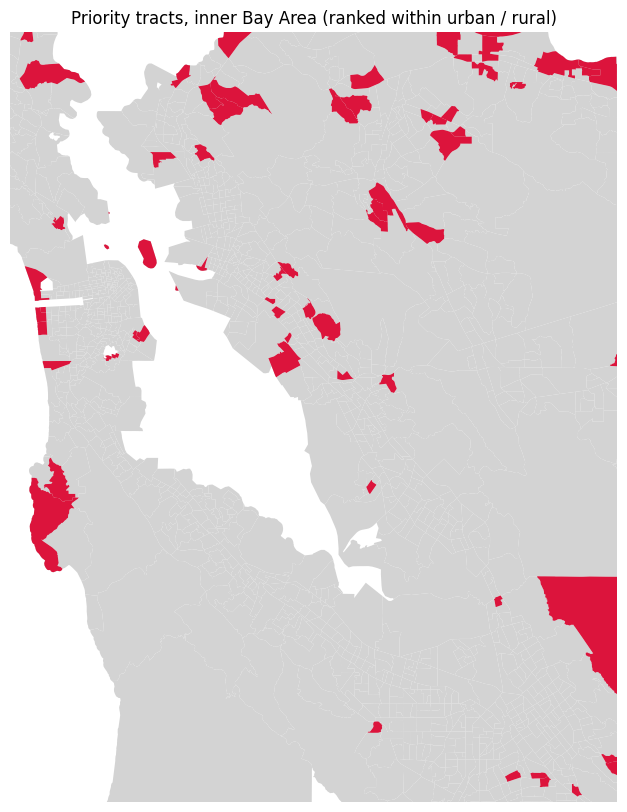

In [28]:
fig, ax = plt.subplots(figsize=(10, 10))
tg.plot(color="lightgrey", ax=ax, linewidth=0)
tg[tg["priority_tract"]].plot(color="crimson", ax=ax, linewidth=0)
ax.set_xlim(-122.55, -121.75); ax.set_ylim(37.25, 38.05)
ax.set_title("Priority tracts, inner Bay Area (ranked within urban / rural)")
ax.axis("off"); plt.show()

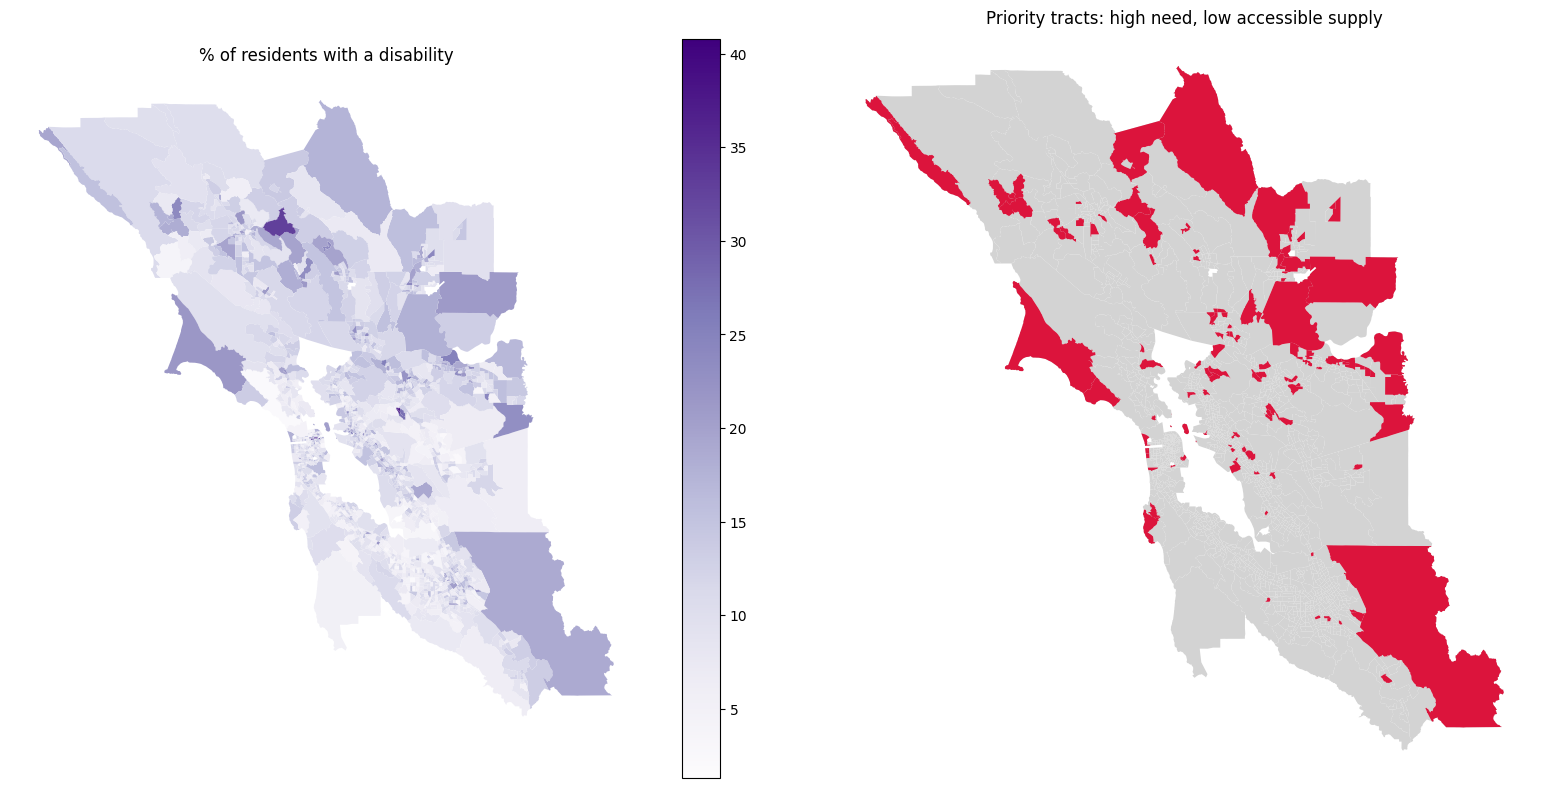

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
tg.plot(column="pct_disabled", cmap="Purples", legend=True, ax=axes[0], linewidth=0)
axes[0].set_title("% of residents with a disability"); axes[0].axis("off")
tg.plot(color="lightgrey", ax=axes[1], linewidth=0)
tg[tg["priority_tract"]].plot(color="crimson", ax=axes[1], linewidth=0)
axes[1].set_title("Priority tracts: high need, low accessible supply"); axes[1].axis("off")
plt.tight_layout(); plt.show()

In [30]:
sf_out = pts[(pts["county"] == "San Francisco") & (~pts["in_paratransit"])]
print(sf_out[["name", "category", "address", "lat", "lon", "dist_any_stop_m"]].head(15))
print(sf_out["dist_any_stop_m"].describe().round(0))

agency = pd.read_csv(f"{gtfs_dir}/agency.txt", dtype=str)
print(agency[["agency_id", "agency_name"]])

Empty DataFrame
Columns: [name, category, address, lat, lon, dist_any_stop_m]
Index: []
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: dist_any_stop_m, dtype: float64
   agency_id                                    agency_name
0         GP             San Francisco Recreation and Parks
1         RV                         Rio Vista Delta Breeze
2         TF                          Treasure Island Ferry
3         EM                                 Emery Go-Round
4         SL                              San Leandro LINKS
5         SI                                    SFO Airport
6         SS                    City of South San Francisco
7         AC                                     AC TRANSIT
8         DE                   Dumbarton Express Consortium
9         3D                              Tri Delta Transit
10        EE                                  Emery Express
11        CC                              County C

In [31]:
pts.drop(columns="geometry").to_pickle(f"{PROCESSED}/places_bay.pkl")
tg.to_file(f"{PROCESSED}/tracts_need_supply.geojson", driver="GeoJSON")
print("Saved.")

Saved.


### Part 5 summary: Need vs. supply

**What we did**
- Pulled disability data for all 1,772 Bay Area census tracts from the ACS 2023 5-year estimates (table S1810) through the Census API, and joined it to Census TIGER/Line 2023 tract boundaries.
- Kept only the 9 Bay Area counties. This reduced the scored places from 106,837 to 101,101, removing Davis, Santa Cruz and other areas our transit data does not cover.
- Dropped 1,088 places with no street address. They shared placeholder coordinates (one point sat in the Bay near Alcatraz) and are home-based, mobile or online services with no door to visit. Most were government and social services (349) and mental health providers (347). **100,013 places remain.**
- Dropped 20 tracts with fewer than 200 residents (parks, airports, water), leaving 1,752 tracts: 1,561 urban/suburban and 191 rural (split at 1,000 residents per sq mile).
- Measured access from each tract's interior point. Urban tracts use a 1-mile radius and rural tracts 5 miles, since rural residents drive.

**Who needs access**
On average, 10.6% of residents in a Bay Area tract have a disability (median 9.9%, middle half 7.3% to 12.7%). The highest tract reaches 54%, likely because of a care facility.

**Finding 1: 118 high-need, low-access tracts**
These tracts are in the top 25% for share of disabled residents *and* the bottom 25% for accessible essential services nearby, ranked within urban and rural areas separately. **79,724 disabled residents** live in them.
- 101 are urban or suburban, led by **Contra Costa (30), Solano (19) and Alameda (13)**.
- 17 are rural, led by Sonoma (7).

**Finding 2: Pharmacy deserts are a supply problem, not an information problem**
- **122,606 disabled residents** (282 tracts) have no pharmacy of any kind within 1 mile (urban) or 5 miles (rural).
- Only **13,569** (30 tracts) live near a pharmacy that does not list its accessibility.
- Urban pharmacy deserts are concentrated in Contra Costa (55 tracts), Alameda (52), Santa Clara (46), Solano (31) and San Mateo (27).
- Checking secondary categories added only 42 pharmacies (1,103 → 1,145) and barely changed the result.
- **Implication:** asking pharmacies to list their features will not close this gap. Delivery, mail-order and mobile pharmacy services aimed at these tracts would.

**Finding 3: 1,661 essential places sit outside the ADA paratransit zone**
These places are more than 3/4 mile from any fixed-route transit stop, so they fall outside the area where agencies must offer paratransit. By county: Solano 381, Santa Clara 375, Sonoma 236, Contra Costa 204, Napa 177, Marin 105, Alameda 92, San Mateo 91 and San Francisco 0.

**Finding 4: The information gap follows the type of place, not the neighborhood**
The share of nearby places with no accessibility info barely tracks the disability rate (r = 0.10). The gap is driven by category instead: mental health providers are 22% unknown, compared with 4% for general health care.

**Method changes we made along the way**
1. *Counting places inside each tract → counting places within a radius.* Tracts are small, and people use services in neighboring tracts. The first version made large rural tracts dominate the map.
2. *One radius everywhere → 1 mile urban, 5 miles rural, ranked separately.* A single 1-mile radius flagged nearly every rural tract, which reflected driving distances rather than missing services.
3. *Main category only → main and secondary categories for pharmacies,* to catch in-store pharmacies.

**Limitations**
- "Accessible" means a physical score of 4 or more out of 5, based on Google's self-reported tags. Places without tags are not counted as accessible, so supply may be understated.
- The ADA zone is measured from stops, not routes, which slightly understates coverage.
- Straight-line distance ignores hills, sidewalks and street layout, which matter a lot for wheelchair users.
- The disability measure covers all disability types, while our accessibility tags mostly cover mobility.
- ACS tract estimates have wide margins of error, especially for small tracts.

## 6. Final accessibility score (0 to 10)

| Component | Points | Rule |
|---|---|---|
| Physical access | 0 to 5 | Confirmed entrance, parking, toilet (toilet only where a public restroom is expected) |
| Transit | 0 to 3 | Distance to nearest usable stop: ≤400m = 3, ≤800m = 2, ≤1.6km = 1 |
| Hours | 0 to 1 | Open evenings (after 6pm) = 0.5, open weekends = 0.5 |
| Paratransit | 0 to 1 | Inside the ADA 3/4-mile paratransit zone |

Places with no physical accessibility info get **no total score** ("Not enough info"), but their transit and hours details are still shown.

In [32]:
def to_hour(s, fallback_pm=None):
    """'7 PM' -> 19, '7:30 pm' -> 19.5, '12 am' -> 24 (midnight). Returns None if unparseable."""
    s = s.strip().lower().replace("\u202f", " ")
    m = re.match(r"(\d{1,2})(?::(\d{2}))?\s*(am|pm)?", s)
    if not m:
        return None
    h, mins, ap = int(m.group(1)), int(m.group(2) or 0), m.group(3) or fallback_pm
    if ap == "pm" and h != 12: h += 12
    if ap == "am" and h == 12: h = 24 if fallback_pm is None else 0
    return h + mins / 60

def hours_info(raw):
    try:
        d = json.loads(raw) if isinstance(raw, str) else None
    except Exception:
        d = None
    if not isinstance(d, dict) or all(v in (None, "") for v in d.values()):
        return pd.Series({"hours_known": False, "open_evening": False, "open_weekend": False})

    evening, weekend = False, False
    for day, val in d.items():
        if not val:
            continue
        v = str(val).lower()
        if "closed" in v:
            continue
        if "24 hours" in v:
            evening = True
            weekend = weekend or day in ("Saturday", "Sunday")
            continue
        if day in ("Saturday", "Sunday"):
            weekend = True
        for seg in v.split("\n"):
            parts = re.split(r"[–-]", seg)
            if len(parts) != 2:
                continue
            end_ap = "pm" if "pm" in parts[1] else ("am" if "am" in parts[1] else None)
            start, end = to_hour(parts[0], end_ap), to_hour(parts[1])
            if end is None:
                continue
            if end > 18 or (start is not None and end < start):   # late close or wraps past midnight
                evening = True
    return pd.Series({"hours_known": True, "open_evening": evening, "open_weekend": weekend})

pts = pts.drop(columns=["hours_known", "open_evening", "open_weekend"], errors="ignore")
pts = pd.concat([pts, pts["open_hours"].apply(hours_info)], axis=1)

pts["hours_score"] = 0.5 * pts["open_evening"] + 0.5 * pts["open_weekend"]
print("Hours known:", round(pts["hours_known"].mean(), 3))
print(pts.loc[pts["hours_known"], ["open_evening", "open_weekend"]].mean().round(3))

Hours known: 0.416
open_evening    0.339
open_weekend    0.357
dtype: float64


In [33]:
check = pts[pts["hours_known"]].sample(8, random_state=7)[["name", "open_hours", "open_evening", "open_weekend"]]
check

,name,open_hours,open_evening,open_weekend
39218,"Bimal J. Patel, MD","{""Friday"":""8 AM–5 PM"",""Monday"":""8 AM–5 PM"",""Saturday"":""Closed"",""Sunday"":""Closed"",""Thursday"":""8 AM–5 PM"",""Tuesday"":""8...",False,False
102103,La Bamba Preschool,"{""Friday"":""9 AM–3 PM"",""Monday"":""9 AM–3 PM"",""Saturday"":""Closed"",""Sunday"":""Closed"",""Thursday"":""9 AM–3 PM"",""Tuesday"":""9...",False,False
140403,Consulate of Lebanon in San Francisco,"{""Friday"":""Closed"",""Monday"":""9:30 am–1:30 pm"",""Saturday"":""Closed"",""Sunday"":""Closed"",""Thursday"":""9:30 am–1:30 pm"",""Tu...",False,False
117149,EQ&O Clinic,"{""Friday"":""11 AM–7 PM"",""Monday"":""10 AM–7 PM"",""Saturday"":""10 AM–7 PM"",""Sunday"":""10 AM–7 PM"",""Thursday"":""10 AM–7 PM"",""...",True,True
83081,"Dr. Veronica A. Cervantes-Prado, DDS","{""Friday"":""9 AM–1 PM"",""Monday"":""9 AM–6 PM"",""Saturday"":""Closed"",""Sunday"":""Closed"",""Thursday"":""9 AM–6 PM"",""Tuesday"":""9...",False,False
50291,Core Gate Acupuncture & Acupressure 核宇针推中心,"{""Friday"":""10 AM–6 PM"",""Monday"":""10 AM–6 PM"",""Saturday"":""10 AM–6 PM"",""Sunday"":""10 AM–6 PM"",""Thursday"":""10 AM–6 PM"",""...",False,True
51747,FFWD (Fast Forward),"{""Friday"":""9 am–5 pm"",""Monday"":""9 am–5 pm"",""Saturday"":""Closed"",""Sunday"":""Closed"",""Thursday"":""9 am–5 pm"",""Tuesday"":""9...",False,False
127509,San Jose Gastroenterology,"{""Friday"":""9 am–5:30 pm"",""Monday"":""9 am–5:30 pm"",""Saturday"":""Closed"",""Sunday"":""Closed"",""Thursday"":""9 am–5:30 pm"",""Tu...",False,False


**Hand check (hours):** 6/8 parsed correctly.

In [34]:
earned   = pts["physical_score"] + pts["transit_score"] + pts["paratransit_pt"] + pts["hours_score"]
possible = 5 + 3 + 1 + pts["hours_known"].astype(int)          # hours only count when listed
pts["total_score"] = (10 * earned / possible).round(1)
pts.loc[pts["physical_score"].isna(), "total_score"] = np.nan

def band(s):
    if pd.isna(s): return "Not enough info"
    if s >= 8:     return "Highly accessible"
    if s >= 5:     return "Partly accessible"
    return "Limited accessibility"

pts["band"] = pts["total_score"].apply(band)

def full_reasons(row):
    out = list(row["reasons"])                       # physical-access reasons from Part 3
    d_conf, d_use = row["dist_confirmed_stop_m"], row["dist_usable_stop_m"]
    if d_conf <= 800:
        out.append(f"✓ Wheelchair-accessible transit stop {int(d_conf)} m away")
    elif d_use <= 800:
        out.append(f"✓ Transit stop {int(d_use)} m away (stop accessibility not recorded)")
    else:
        out.append(f"✗ Nearest usable transit stop is {int(d_use)} m away")
    out.append("✓ Inside ADA paratransit zone" if row["in_paratransit"]
               else "✗ Outside ADA paratransit zone (over 3/4 mile from fixed-route transit)")
    if not row["hours_known"]:
        out.append("? Hours not listed")
    else:
        out.append("✓ Open evenings" if row["open_evening"] else "✗ Closes before 6 pm")
        out.append("✓ Open weekends" if row["open_weekend"] else "✗ Closed on weekends")
    return out

pts["reasons_full"] = pts.apply(full_reasons, axis=1)

print(pts["band"].value_counts(normalize=True).round(3))
print(pts.groupby("group")["total_score"].agg(["mean", "median"]).round(2).sort_values("mean"))

band
Highly accessible        0.746
Partly accessible        0.161
Not enough info          0.078
Limited accessibility    0.014
Name: proportion, dtype: float64
                        mean  median
group                               
Gov & social services   7.77     8.0
Mental health           7.83     8.3
Education & child care  8.13     9.0
Financial               9.10     9.5
Recreation              9.15     9.5
Health care             9.32    10.0
Pharmacy                9.37    10.0
Food                    9.39    10.0


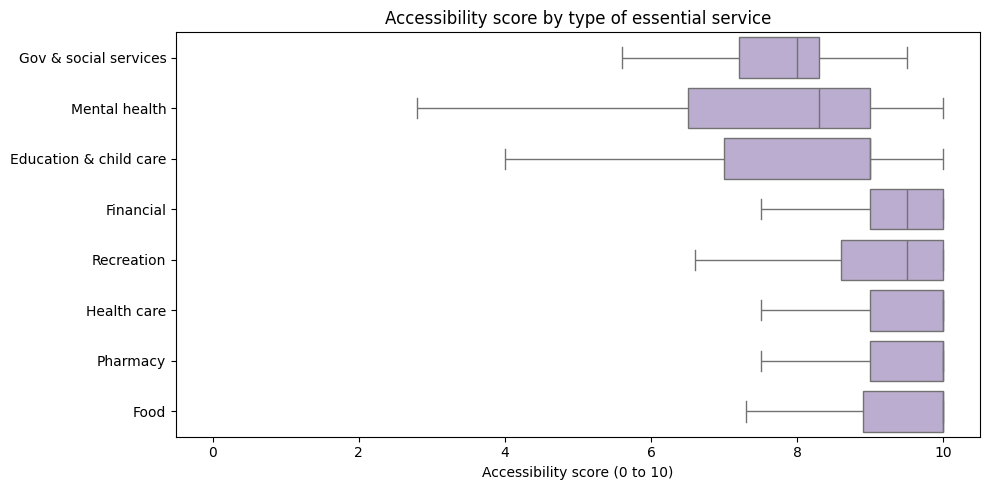

In [35]:
order = pts.groupby("group")["total_score"].mean().sort_values().index
plt.figure(figsize=(10, 5))
sns.boxplot(data=pts, x="total_score", y="group", order=order, color="#b9a7d6", fliersize=0)
plt.xlabel("Accessibility score (0 to 10)"); plt.ylabel("")
plt.title("Accessibility score by type of essential service")
plt.tight_layout(); plt.show()

In [36]:
for _, r in pts.dropna(subset=["total_score"]).sample(3, random_state=3).iterrows():
    print(f"{r['name']}  ({r['category']}, {r['county']})")
    print(f"  Score: {r['total_score']}/10  [{r['band']}]  confidence: {r['confidence']}")
    for line in r["reasons_full"]:
        print("   ", line)
    print()

Chun Jarn H DDS  (Dentist, Alameda)
  Score: 10.0/10  [Highly accessible]  confidence: Confirmed
    ✓ Wheelchair-accessible entrance
    ✓ Wheelchair-accessible toilet
    ✓ Wheelchair-accessible parking
    ✓ Transit stop 90 m away (stop accessibility not recorded)
    ✓ Inside ADA paratransit zone
    ? Hours not listed

Oteyza Elaina MD  (Doctor, Solano)
  Score: 8.3/10  [Highly accessible]  confidence: Partial
    ✓ Wheelchair-accessible entrance
    ? Toilet accessibility not listed
    ✓ Wheelchair-accessible parking
    ✓ Wheelchair-accessible transit stop 238 m away
    ✓ Inside ADA paratransit zone
    ? Hours not listed

Peter Adler, PhD  (Psychologist, Santa Clara)
  Score: 8.3/10  [Highly accessible]  confidence: Partial
    ✓ Wheelchair-accessible entrance
    ? Toilet accessibility not listed
    ✓ Wheelchair-accessible parking
    ✓ Wheelchair-accessible transit stop 111 m away
    ✓ Inside ADA paratransit zone
    ? Hours not listed



**Scoring rule:** Accessibility features earn points only when *confirmed*, because the score answers "can I be sure I can get in?" Hours are convenience information, so when hours are not listed they are left out and the score is scaled to 10 from the remaining components.

### Review excerpts for the website
For each place, pick up to 3 short review excerpts: the highest-rated, the lowest-rated, and one that mentions accessibility if available.
Sources: the Places `top_reviews` column and the Google Maps Reviews dataset (joined on place_id).
Reviewer names, photos and links are never kept. Excerpts are cut to about 220 characters.

In [37]:
ex = pts["top_reviews"].dropna().iloc[0]
print(json.loads(ex)[0].keys() if isinstance(ex, str) else ex)
print("Places with top_reviews:", pts["top_reviews"].notna().sum())

dict_keys(['content', 'rating', 'review_date', 'reviewer_image_url', 'reviewer_name', 'reviewer_photos_number', 'reviewer_reviews_number'])
Places with top_reviews: 43424


In [38]:
reviews = pd.read_csv(REVIEWS_PATH, usecols=["place_id", "review", "review_rating"])

STRONG = (r"\bwheel ?chairs?\b|\bhandicap(?:ped)?\b|\bdisabled\b|\bdisabilit(?:y|ies)\b|\bADA\b|"
          r"\bramps?\b|\bbraille\b|\bdeaf\b|\bASL\b|\bsign language\b|\bblind\b|"
          r"\bservice (?:dog|animal)\b|\bwalker\b|\bmobility\b|\bcrutches\b")

def clip(text, n=220):
    t = " ".join(str(text).split())
    return t if len(t) <= n else t[:n].rsplit(" ", 1)[0] + "…"

def from_top_reviews(raw):
    out = []
    for d in parse_list(raw):
        if not isinstance(d, dict):
            continue
        text = d.get("content") or d.get("review") or d.get("text")
        stars = d.get("rating") or d.get("review_rating") or d.get("stars")
        if text:
            out.append({"text": text, "stars": stars})
    return out

# Collect candidates per place from both sources
cands = {pid: from_top_reviews(raw) for pid, raw in zip(pts["place_id"], pts["top_reviews"])}
for pid, text, stars in reviews[reviews["place_id"].isin(cands)][["place_id", "review", "review_rating"]].itertuples(index=False):
    if isinstance(text, str):
        cands[pid].append({"text": text, "stars": stars})

def pick(items):
    seen, clean = set(), []
    for it in items:
        t = " ".join(str(it["text"]).split())
        if len(t) < 30 or t[:60] in seen:
            continue
        seen.add(t[:60])
        clean.append({"text": t, "stars": it["stars"], "access": bool(re.search(STRONG, t, re.I))})
    if not clean:
        return None
    rated = [c for c in clean if c["stars"] is not None and str(c["stars"]).replace(".", "").isdigit()]
    chosen = []
    access = [c for c in clean if c["access"]]
    if access:
        chosen.append(access[0])
    if rated:
        hi = max(rated, key=lambda c: float(c["stars"]))
        lo = min(rated, key=lambda c: float(c["stars"]))
        for c in (hi, lo):
            if c not in chosen and (c is hi or float(c["stars"]) <= 3):
                chosen.append(c)
    for c in clean:
        if len(chosen) >= 3:
            break
        if c not in chosen:
            chosen.append(c)
    chosen = chosen[:3]
    return json.dumps([{"text": clip(c["text"]),
                        "stars": float(c["stars"]) if c in rated else None,
                        "access": c["access"]} for c in chosen])

pts["review_samples"] = pts["place_id"].map(lambda pid: pick(cands.get(pid, [])))
print("Places with review excerpts:", pts["review_samples"].notna().sum(), "of", len(pts))
print("…with an accessibility mention:", pts["review_samples"].fillna("").str.contains('"access": true').sum())

Places with review excerpts: 37009 of 100013
…with an accessibility mention: 1359


In [39]:
for raw in pts["review_samples"].dropna().sample(3, random_state=1):
    for it in json.loads(raw):
        print(it["stars"], "|", it["access"], "|", it["text"])
    print("---")

5.0 | False | Good location. Easy parking. Line moved quickly. Teller was friendly and helpful.
1.0 | False | The cashiers are very slow and relaxed. They only let one person pass in 20 minutes. They ask too many questions. I had a problem with payment and we waited a long time. They were chatting. It's like they forgot that…
1.0 | False | Avoid location when black when you seek to access your own money
---
5.0 | False | We couldn’t be happier with Dr. Malik as our daughter’s pediatrician! She is attentive, caring, and always takes the time to address our concerns without ever making us feel rushed. Her responsiveness is outstanding, we…
5.0 | False | Our daughter’s pediatrician, highly recommended!! Definitely go for her!!
5.0 | False | She is a wonderful pediatrician who even follows up with you about your child health even if you move to different state. She has treated my kid with lot of patience, concern and diagnosed her properly even when the…
---
5.0 | False | We have had such 

In [40]:
has = pts[pts["review_samples"].notna()]
print(has[has["review_samples"].str.contains('"access": true')][["name"]].head(5))
print(has[["name"]].sample(5, random_state=2))

                                                name
12                        Bill Wilson Drop-in Center
62   Dr. Milagros Cabrera, Obstetrician-gynecologist
106                                  Mojgan Ebadi MD
163         Veterans Supportive Services Agency, Inc
164                       Macarthur Gastroenterology
                                                                                       name
130962                                                                     Nicholas Froumis
52340                                                              Vallejo Building Permits
6841                                                              Dr. Leslie A. Schmidt, MD
98202                                                                             ExtraMile
52264   Stanford Medicine Children’s Health Orthopedics and Sports Medicine – Pleasant Hill


In [41]:
city_mode = (pts.assign(city=pts["address"].str.split(",").str[-3].str.strip())
               .groupby("GEOID")["city"]
               .agg(lambda s: s.mode().iat[0] if not s.mode().empty else ""))
tg["main_city"] = tg["GEOID"].map(city_mode).fillna("")

### Export for the website
One row per place with everything the app needs. Tract context (disability rate, priority flag) is attached so the app can show neighborhood info.

*Note: Part 9 adds parks and outdoor places to this same file, so the final `places_app.parquet` is written at the end of Part 9.*

In [42]:
tract_cols = tg[["GEOID", "pct_disabled", "priority_tract", "setting"]]
app = pts.merge(tract_cols, on="GEOID", how="left")

app["city"] = app["address"].str.split(",").str[-3].str.strip()
app["reasons_text"] = app["reasons_full"].apply(lambda xs: " | ".join(xs))
app["reviews_count"] = app["reviews_count"].fillna(0).astype(int)

keep = ["place_id", "name", "category", "group", "address", "city", "county", "lat", "lon",
        "rating", "reviews_count", "phone_number", "open_website",
        "entrance", "parking", "toilet", "seating", "hearing_loop",
        "physical_score", "transit_score", "hours_score", "paratransit_pt", "total_score",
        "band", "confidence", "reasons_text",
        "dist_usable_stop_m", "dist_confirmed_stop_m", "in_paratransit",
        "pct_disabled", "priority_tract", "setting", "hours_known", "open_evening", "open_weekend", "review_samples"]
app = app[keep]

app.to_csv(f"{PROCESSED}/places_app.csv", index=False)
print(len(app), "rows |", round(os.path.getsize(f"{PROCESSED}/places_app.csv") / 1e6, 1), "MB")

# Lighter tract shapes for the neighborhood tab
tg_small = tg[["GEOID", "county", "main_city", "setting", "pop_total", "pop_disabled", "pct_disabled",
               "acc_nearby", "priority_tract", "dist_acc_pharmacy_m", "dist_acc_food_m", "geometry"]].copy()
tg_small["geometry"] = tg_small.to_crs(3310).simplify(50).to_crs(4326)
tg_small.to_file(f"{PROCESSED}/tracts_app.geojson", driver="GeoJSON")
print("tracts_app.geojson:", round(os.path.getsize(f"{PROCESSED}/tracts_app.geojson") / 1e6, 1), "MB")

app.to_parquet(f"{PROCESSED}/places_app.parquet", index=False)
print("parquet:", round(os.path.getsize(f"{PROCESSED}/places_app.parquet") / 1e6, 1), "MB")

100013 rows | 82.5 MB
tracts_app.geojson: 1.6 MB
parquet: 24.6 MB


### Part 6 findings
- 74.6% of essential places score as highly accessible (8+), 16.1% partly accessible, 1.4% limited, and 7.8% lack enough information to score.
- Government and social services (mean 7.8) and mental health providers (7.8) score lowest, and are also the least documented. Food, pharmacies and health care average about 9.3 to 9.4.
- Only 42% of places list opening hours. Of those, 34% stay open after 6pm and 36% open on weekends.
- Hand check (hours parser): 6/8 correct on first pass; places closing at exactly 6pm were wrongly counted as "open evenings." Fixed and rechecked.

## 7. Validation: Street View spot check
Do Google's accessibility tags match what the entrance actually looks like?
We sampled 20 places tagged "wheelchair-accessible entrance" and 10 with no entrance info, and checked each entrance on Google Street View.

In [43]:
ess = pts[pts["group"] != "Recreation"]
check = pd.concat([
    ess[ess["entrance"] == "yes"].sample(20, random_state=11).assign(sample="Tagged accessible"),
    ess[ess["entrance"] == "unknown"].sample(10, random_state=11).assign(sample="No entrance info"),
])
check = check[["sample", "name", "category", "address"]].assign(
    maps_link="https://www.google.com/maps/place/?q=place_id:" + check["place_id"],
    what_i_saw="",      # Step-free / Ramp / Steps only / Can't tell
    notes="",
)

blank_path = f"{PROCESSED}/streetview_check_blank.csv"
if not os.path.exists(blank_path):              # never overwrite the sheet once created
    check.to_csv(blank_path, index=False)
print("Sample of", len(check), "places (blank sheet:", os.path.basename(blank_path), ")")

Sample of 30 places (blank sheet: streetview_check_blank.csv )


In [44]:
path = f"{PROCESSED}/streetview_check_filled.csv"
sv = pd.read_csv(path)
print("Loaded:", os.path.basename(path), "|", len(sv), "rows")

def norm(x):
    x = str(x).strip().lower()
    if "step" in x and "free" in x: return "Step-free"
    if "ramp" in x:                 return "Ramp"
    if "step" in x:                 return "Steps only"
    return "Can't tell"

sv["seen"] = sv["what_i_saw"].apply(norm)
sv["looks_accessible"] = sv["seen"].isin(["Step-free", "Ramp"])
print(pd.crosstab(sv["sample"], sv["seen"], margins=True))

def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (round(100 * (c - h)), round(100 * (c + h)))

for s in ["Tagged accessible", "No entrance info"]:
    g = sv[(sv["sample"] == s) & (sv["seen"] != "Can't tell")]
    k, n = int(g["looks_accessible"].sum()), len(g)
    lo, hi = wilson(k, n)
    cant = int(((sv["sample"] == s) & (sv["seen"] == "Can't tell")).sum())
    print(f"\n{s}: {k} of {n} visible entrances looked step-free or ramped "
          f"({k / n:.0%}, 95% CI {lo}% to {hi}%); {cant} could not be seen")

print("\nMismatches (tagged accessible, but steps only):")
print(sv[(sv["sample"] == "Tagged accessible") & (sv["seen"] == "Steps only")][["name", "address", "notes"]])

Loaded: streetview_check_filled.csv | 30 rows
seen               Can't tell  Ramp  Step-free  Steps only  All
sample                                                         
No entrance info            1     2          6           1   10
Tagged accessible           4     9          7           0   20
All                         5    11         13           1   30

Tagged accessible: 16 of 16 visible entrances looked step-free or ramped (100%, 95% CI 81% to 100%); 4 could not be seen

No entrance info: 8 of 9 visible entrances looked step-free or ramped (89%, 95% CI 56% to 98%); 1 could not be seen

Mismatches (tagged accessible, but steps only):
Empty DataFrame
Columns: [name, address, notes]
Index: []


### Part 7 findings
- **Tags hold up:** All 16 places tagged "wheelchair-accessible entrance" whose entrance was visible on Street View had a step-free (7) or ramped (9) entrance (95% CI 81% to 100%). No tagged place showed steps only. 4 of the 20 could not be seen clearly.
- **Missing info is not the same as inaccessible:** 8 of the 9 visible places with *no* entrance info also looked step-free (6) or ramped (2) (89%, 95% CI 56% to 98%). Only 1 showed steps only, and 1 could not be seen. This supports showing these places as "Not enough info" instead of scoring them as zero, and it suggests most of the gap is missing information, not missing ramps.
- **What this means for the recommendation:** An outreach drive asking businesses to list their accessibility features would likely reveal many accessible entrances that are invisible today, especially among mental health providers and government offices.
- **Limits:** Street View images can be several years old, usually show only the front entrance, and cannot confirm door width, automatic doors, restrooms or interior steps. With 30 places, this is a sanity check rather than a full audit, and the confidence intervals are wide, especially for the 9 untagged places.

## 8. Reviews: lived experience
What do reviewers say when they mention accessibility? We search all ~100,000 Bay Area reviews (not only essential services, since only ~3,000 reviews match our places) for accessibility language, hand-check the matches, then group them into themes and compare their star ratings with other reviews.
Reviewer names are never displayed, and only short excerpts are quoted.

In [45]:
rev = pd.read_csv(REVIEWS_PATH, usecols=["place_id", "place_name", "review", "review_rating"])
rev = rev[rev["review"].notna() & (rev["review"].str.len() >= 30)].copy()

STRONG = (r"\bwheel ?chairs?\b|\bhandicap(?:ped)?\b|\bdisabled\b|\bdisabilit(?:y|ies)\b|\bADA\b|"
          r"\bramps?\b|\bbraille\b|\bdeaf\b|\bASL\b|\bsign language\b|\bblind\b|"
          r"\bservice (?:dog|animal)\b|\bwalker\b|\bmobility\b|\bcrutches\b|\bparatransit\b|\bcane\b")
WEAK    = r"\belevators?\b|\bstairs\b|\bsteps\b"
BROKEN  = r"broken|out of order|not working|stuck|no elevator|only stairs|lots of stairs|flight of stairs"
EXCLUDE = (r"disability (?:insurance|benefits|claim|leave)|blind spot|\bblinds?\b(?! (?:person|people|guest|customer|man|woman|friend|mother|father|son|daughter))|"
           r"window blind|sugar cane|candy cane|ramp(?:ed)? up|(?:on|off|on/off|freeway|highway|exit) ?ramps?|"
           r"next steps|few steps away|steps? (?:from|away)|the steps (?:to|of) (?:the )?process")

txt = rev["review"]
rev["access_mention"] = ((txt.str.contains(STRONG, case=False) |
                          (txt.str.contains(WEAK, case=False) & txt.str.contains(BROKEN, case=False)))
                         & ~txt.str.contains(EXCLUDE, case=False))
print(rev["access_mention"].sum(), "of", len(rev), "reviews mention accessibility",
      f"({rev['access_mention'].mean():.1%})")

2158 of 198697 reviews mention accessibility (1.1%)


In [46]:
pat = re.compile(f"({STRONG})|({WEAK})", re.I)
for i, r in enumerate(rev[rev["access_mention"]].sample(20, random_state=9)["review"], 1):
    r = " ".join(r.split())
    m = pat.search(r)
    s = max(0, m.start() - 90) if m else 0
    snippet = r[s:s + 200]
    if m:
        snippet = snippet.replace(m.group(0), f"[[{m.group(0).upper()}]]", 1)
    print(f"{i:>2}. …{snippet}…\n")

 1. …, to dampen the buses, trucks, and druggies yelling down below. Worth noting, there is no [[ELEVATOR]]. At a bargain of $85 for a Friday night in November, you definitely get what you pay for here but I’m…

 2. …Great location and price. Arrived with our [[SERVICE DOG]] and informed front desk upon arrival. I was asked to provide documentation (illegal). Provided documentation, then was asked about my specific me…

 3. …reakfast, restaurants, checkout time, etc. My room is on the second floor and there is no [[ELEVATOR]]. If you have to carry heavy bags, I’d skip this hotel or ask for a 1st floor room. Got to my room and…

 4. …jacuzzi jets didnt work, make sure you can carry you luggage upstairs because there is no [[ELEVATOR]]. This place does not live up to the Ramada name and I'm surprised Wyndham would put their name on it.…

 5. …oor. An obvious amount - I have pictures 2. Moved to another room with plumbing issues 3. [[ELEVATOR]] is extremely slow if catching an Uber you ma

**Hand check (keyword matching):** After tightening the exclusions, 16 of 20 newly sampled matches were clearly about accessibility (precision ≈ 80%), and 1 more was borderline. Real matches covered missing or broken elevators, service-dog treatment, accessible parking and rooms, and disabled guests describing their stay. The 3 false positives came from "elevator" or "steps" appearing in unrelated complaints.
A first pass had only ≈ 50% precision (e.g. "window blind", "freeway on/off ramps"); we added exclusions and re-checked on a fresh random sample.
**Definition:** we count a review as an accessibility mention if it describes a disability-related experience or a physical barrier such as no working elevator, even if the reviewer does not say they are disabled.

In [47]:
THEMES = {
    "Entrance, ramps & steps":   r"\bramps?\b|\bsteps?\b|\bstairs\b|entrance|curb",
    "Elevators":                 r"\belevators?\b|\blift\b",
    "Parking & drop-off":        r"handicap(?:ped)? parking|accessible parking|disabled parking|\bparking\b|drop[- ]off",
    "Restrooms":                 r"restroom|bathroom|toilet|washroom|stall",
    "Staff attitude & help":     r"staff|employee|rude|kind|helpful|patient|respect|treated|ignored|accommodat",
    "Space, seating & waiting":  r"\bseat|\bchairs?\b|narrow|space|aisle|crowded|wait(?:ed|ing)?\b|stand",
    "Hearing & communication":   r"\bdeaf\b|\bASL\b|sign language|hearing|interpreter",
    "Vision":                    r"\bblind\b|braille|low vision|visually impaired",
    "Service animals":           r"service (?:dog|animal)",
}

acc = rev[rev["access_mention"]].copy()
rows = []
for theme, pat in THEMES.items():
    m = acc["review"].str.contains(pat, case=False)
    sub = acc[m]
    rows.append({"theme": theme, "reviews": int(m.sum()),
                 "share_of_access_reviews": m.mean(),
                 "mean_stars": sub["review_rating"].mean(),
                 "share_negative": (sub["review_rating"] <= 2).mean()})
themes = pd.DataFrame(rows).sort_values("reviews", ascending=False)
print(themes.round(2).to_string(index=False))

print("\nAll reviews:            mean stars", round(rev["review_rating"].mean(), 2),
      "| share 1 to 2 stars", f"{(rev['review_rating'] <= 2).mean():.0%}")
print("Accessibility reviews:  mean stars", round(acc["review_rating"].mean(), 2),
      "| share 1 to 2 stars", f"{(acc['review_rating'] <= 2).mean():.0%}")

                   theme  reviews  share_of_access_reviews  mean_stars  share_negative
   Staff attitude & help     1072                     0.50        1.97            0.65
               Elevators     1051                     0.49        1.56            0.75
Space, seating & waiting      596                     0.28        1.73            0.70
               Restrooms      507                     0.23        1.62            0.73
 Entrance, ramps & steps      452                     0.21        2.04            0.63
      Parking & drop-off      376                     0.17        1.95            0.64
         Service animals      135                     0.06        1.46            0.81
 Hearing & communication       37                     0.02        2.35            0.59
                  Vision       10                     0.00        3.00            0.40

All reviews:            mean stars 3.33 | share 1 to 2 stars 34%
Accessibility reviews:  mean stars 1.89 | share 1 to 2 stars 67%

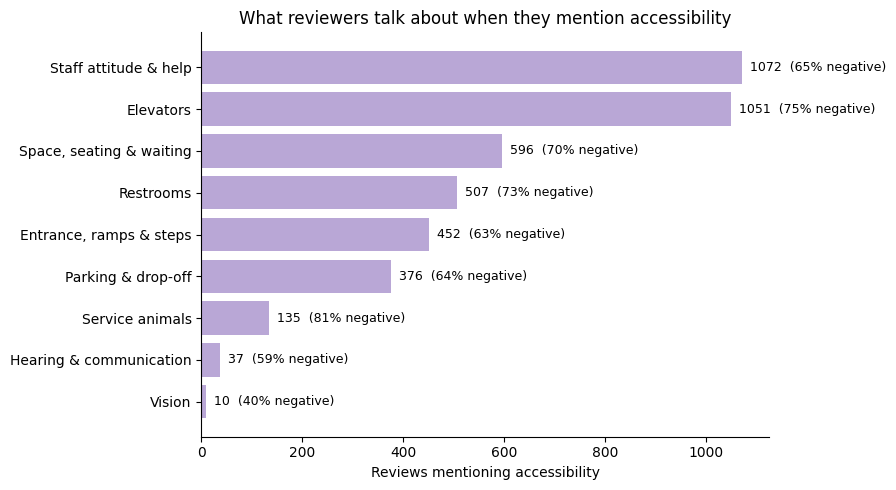

In [48]:
plot = themes[themes["reviews"] >= 10].sort_values("reviews")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot["theme"], plot["reviews"], color="#b9a7d6")
for y, (n, neg) in enumerate(zip(plot["reviews"], plot["share_negative"])):
    ax.text(n, y, f"  {n}  ({neg:.0%} negative)", va="center", fontsize=9)
ax.set_xlabel("Reviews mentioning accessibility")
ax.set_title("What reviewers talk about when they mention accessibility")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [49]:
for theme in themes["theme"].head(5):
    sub = acc[acc["review"].str.contains(THEMES[theme], case=False)]
    print(f"=== {theme} ===")
    for label, part in [("LOW", sub[sub["review_rating"] <= 2]), ("HIGH", sub[sub["review_rating"] >= 4])]:
        for r in part["review"].head(2):
            print(f"  [{label}] {' '.join(r.split())[:180]}")
    print()

=== Staff attitude & help ===
  [LOW] Rooms: First and foremost, the room is trashy! The carpets are filthy! Caked in sticky, and slimy stuff. The beds were half made bad the blankets on the floor. No microwave. No fre
  [LOW] Convenient location, but disappointing conditions This Hilton Garden Inn has a great location just off the expressway and within walking distance of several restaurants and a Walma
  [HIGH] Nice room, great staff, room service never called back twice over an hour so I was late for spa services and missed several; but they helped me reschedule the last one at least bef
  [HIGH] My house was struck by lightning and lost power and had to stay in a hotel. First couple nights I had booked thru 3rd party and double beds I have bad back and hips beds were not c

=== Elevators ===
  [LOW] Convenient location, but disappointing conditions This Hilton Garden Inn has a great location just off the expressway and within walking distance of several restaurants and a Walma
  [L

### Part 8 findings
- **Accessibility rarely comes up:** about 2,158 of 198,697 reviews (1.1%) mention accessibility (hand-checked precision ≈ 80%). A place's star rating therefore tells a disabled visitor almost nothing about whether they can get in, which is why AccessBay scores places on listed features rather than ratings.
- **When it comes up, something usually went wrong:** reviews that mention accessibility average **1.89 stars**, compared with **3.33** for all reviews, and **67% are 1 to 2 stars** (vs 34% overall). Accessibility tends to get noticed when it fails.
- **How people are treated matters as much as the building:** half of accessibility reviews (1,072) also talk about staff (helpfulness, rudeness, being ignored or accommodated). Physical features alone do not capture the experience.
- **Elevators are the most common physical barrier** (1,051 reviews, 75% negative, mean 1.56 stars): missing, broken or far from rooms. Restrooms (73% negative) and space and seating (70%) follow.
- **Service animal reviews are the most negative theme** (135 reviews, 81% negative, mean 1.46 stars), often describing staff demanding documentation or refusing entry.
- **Hearing and vision access are nearly invisible:** only 37 and 10 reviews, matching the near-absence of hearing and vision information in Google's tags (77 places list a hearing loop). This is a blind spot in the data, not evidence that these needs are met.
- **Selected quotes (no names):**
  - "I would not recommend this hotel, especially for elderly guests, those with disabilities, or anyone with poor vision."
  - "I've never in my life been to a hotel that doesn't have handicap parking."
  - "I was asked to provide documentation (illegal)." (service dog)
  - "Was given small room that made movement difficult for an 80 year old couple."

**Limits**
- **Skewed toward extremes:** people mostly review after very good or very bad visits.
- **Mostly hotels and travel:** few matches come from essential services, so these themes describe disabled customers' experiences in general.
- **Keyword matching:** misses barriers described in other words; about 20% of matches are false positives.
- **Themes overlap, and "staff" is broad:** one review can count toward several themes, and the staff theme catches any mention of staff, not only how disabled guests were treated.
- **Reviewers are not representative:** most people with disabilities never write reviews, and we cannot tell whether a reviewer is disabled.

The file held ~199k rows rather than the ~100k described in the README; all rows were kept, so some duplicates may remain.

## 9. Recreation: parks, beaches, playgrounds and trails (OpenStreetMap)
Disabled residents deserve access to outdoor and recreational spaces, not only essential services.
Source: OpenStreetMap (© OpenStreetMap contributors, ODbL), downloaded per county with `osmnx`.
For each named park, beach, playground, garden, nature reserve and dog park we check:
- is the place itself tagged wheelchair accessible (yes / limited / no)?
- is there a wheelchair-accessible path or trail in or next to it (within 50 m)?
- is there a wheelchair-accessible restroom within 300 m?
- is there accessible parking within 300 m?
Physical score (0 to 5): place tagged accessible 2 (limited 1), accessible path 1.5 (limited 0.75), accessible restroom 1, accessible parking 0.5. Transit and paratransit are added exactly as in Part 6. Parks have no hours, so the total is scaled to 10 from the remaining 9 points.

In [50]:
import osmnx as ox, time
ox.settings.requests_timeout = 600
ox.settings.use_cache = True
ox.settings.cache_folder = f"{EXTERNAL}/osm_cache"

county_shapes = tracts.to_crs(4326).dissolve("county")[["geometry"]]
KEEP = ["name", "leisure", "natural", "amenity", "highway", "wheelchair", "toilets:wheelchair",
        "capacity:disabled", "parking_space", "access", "geometry"]
QUERIES = {
    "rec":      {"leisure": ["park", "playground", "nature_reserve", "garden", "dog_park"], "natural": "beach"},
    "wheel":    {"wheelchair": True},                    # anything tagged with wheelchair info (paths, trails…)
    "toilets":  {"amenity": "toilets"},
    "dparking": {"capacity:disabled": True, "parking_space": "disabled"},
}

def std(g):
    g = g.rename(columns={"element_type": "element", "osmid": "id"})
    for c in KEEP:
        if c not in g.columns:
            g[c] = None
    return g

def fetch(name, tags):
    path = f"{EXTERNAL}/osm_{name}.parquet"
    if os.path.exists(path):
        return std(gpd.read_parquet(path))
    parts = []
    for county, row in county_shapes.iterrows():
        t0 = time.time()
        try:
            g = ox.features_from_polygon(row.geometry, tags)
            g = g[[c for c in KEEP if c in g.columns]].copy()
            parts.append(g)
            print(f"  {name:<9} {county:<14} {len(g):>6} features ({time.time() - t0:.0f}s)")
        except Exception as e:
            print(f"  {name:<9} {county:<14} none or error: {type(e).__name__}")
    out = pd.concat(parts)
    out = out[~out.index.duplicated()]
    out = gpd.GeoDataFrame(out, geometry="geometry", crs=4326).reset_index()
    for c in out.columns:                                   # parquet can't store mixed object types
        if c != "geometry" and out[c].dtype == object:
            out[c] = out[c].astype(str).replace({"nan": None, "None": None})
    out.to_parquet(path)
    return std(gpd.read_parquet(path))

osm = {k: fetch(k, v) for k, v in QUERIES.items()}
for k, g in osm.items():
    print(k, len(g))

  rec       Alameda          2715 features (1s)
  rec       Contra Costa     1729 features (1s)
  rec       Marin             676 features (1s)
  rec       Napa           none or error: ResponseStatusCodeError
  rec       San Francisco    2420 features (1s)
  rec       San Mateo        1350 features (1s)
  rec       Santa Clara      3684 features (2s)
  rec       Solano         none or error: ResponseStatusCodeError
  rec       Sonoma         none or error: ResponseStatusCodeError
rec 12526
wheel 22949
toilets 2868
dparking 2426


**Notes:** OpenStreetMap’s public server rejected some requests under load, so failed counties were refetched with retries and a backup server.

In [51]:
FAILED = {"rec": {"Napa", "Solano", "Sonoma"}, "wheel": {"Sonoma"}, "dparking": {"Napa", "Sonoma"}}
MISSING = []

def fetch_final(name, tags):
    parts = []
    for county, row in county_shapes.iterrows():
        if county in FAILED[name]:          # skipped: public server kept timing out
            MISSING.append((name, county))
            print(f"  {name:<9} {county:<14} SKIPPED (server timeouts)")
            continue
        t0 = time.time()
        g = ox.features_from_polygon(row.geometry, tags)
        parts.append(g[[c for c in KEEP if c in g.columns]].copy())
        print(f"  {name:<9} {county:<14} {len(g):>6} features ({time.time() - t0:.0f}s)")
    out = pd.concat(parts)
    out = out[~out.index.duplicated()]
    out = gpd.GeoDataFrame(out, geometry="geometry", crs=4326).reset_index()
    for c in out.columns:
        if c != "geometry" and out[c].dtype == object:
            out[c] = out[c].astype(str).replace({"nan": None, "None": None})
    out.to_parquet(f"{EXTERNAL}/osm_{name}.parquet")
    return std(gpd.read_parquet(f"{EXTERNAL}/osm_{name}.parquet"))

for k in ["rec", "wheel", "dparking"]:
    osm[k] = fetch_final(k, QUERIES[k])
print("\nSkipped:", MISSING)
for k, g in osm.items():
    print(k, len(g))

  rec       Alameda          2715 features (1s)
  rec       Contra Costa     1729 features (1s)
  rec       Marin             676 features (2s)
  rec       Napa           SKIPPED (server timeouts)
  rec       San Francisco    2420 features (1s)
  rec       San Mateo        1350 features (1s)
  rec       Santa Clara      3684 features (1s)
  rec       Solano         SKIPPED (server timeouts)
  rec       Sonoma         SKIPPED (server timeouts)
  wheel     Alameda          5323 features (1s)
  wheel     Contra Costa     2005 features (1s)
  wheel     Marin             712 features (0s)
  wheel     Napa               43 features (1s)
  wheel     San Francisco    9088 features (2s)
  wheel     San Mateo        1559 features (1s)
  wheel     Santa Clara      3864 features (2s)
  wheel     Solano            365 features (1s)
  wheel     Sonoma         SKIPPED (server timeouts)
  dparking  Alameda           584 features (1s)
  dparking  Contra Costa      154 features (1s)
  dparking  Marin   

**Note:** OpenStreetMap's public server repeatedly timed out for parts of the North Bay. After retries failed, those counties were skipped (parks: Napa, Solano, Sonoma; wheelchair paths: Sonoma; accessible parking: Napa, Sonoma).

In [52]:
M = 3310   # California Albers, units in meters

g = osm["rec"].copy()
g = g[g["name"].notna() & ~g["access"].isin(["private", "no"])].to_crs(M)
g["rec_type"] = np.select(
    [g["natural"].eq("beach"), g["leisure"].eq("playground"), g["leisure"].eq("nature_reserve"),
     g["leisure"].eq("garden"), g["leisure"].eq("dog_park")],
    ["Beach", "Playground", "Nature reserve", "Garden", "Dog park"], default="Park")
g = g.reset_index(drop=True)
g["zone"] = gpd.GeoSeries([geom if geom.area > 0 else geom.buffer(50) for geom in g.geometry], crs=M)

def status_from(vals):
    v = {str(x).lower() for x in vals}
    if v & {"yes", "designated"}: return "yes"
    if "limited" in v:            return "limited"
    if "no" in v:                 return "no"
    return "unknown"

def near(features, dist):
    f = features.to_crs(M)[["wheelchair", "toilets:wheelchair", "geometry"]]
    z = gpd.GeoDataFrame({"rid": g.index}, geometry=g["zone"].buffer(dist), crs=M)
    return gpd.sjoin(f, z, predicate="intersects")

# 1. Is the place itself tagged?
g["entrance"] = g["wheelchair"].apply(lambda x: status_from([x]))

# 2. Wheelchair-tagged paths / trails within 50 m
wheel = osm["wheel"]
paths = wheel[wheel["highway"].isin(["path", "footway", "cycleway", "track", "pedestrian", "steps"])]
j = near(paths, 50)
g["trail"] = j.groupby("rid")["wheelchair"].apply(status_from).reindex(g.index).fillna("unknown")

# 3. Restrooms within 300 m
toil = osm["toilets"].copy()
toil["wheelchair"] = toil["wheelchair"].fillna(toil["toilets:wheelchair"])
j = near(toil, 300)
g["toilet"] = j.groupby("rid")["wheelchair"].apply(
    lambda v: "yes" if status_from(v) == "yes" else ("no" if "no" in {str(x).lower() for x in v} else "unknown")
).reindex(g.index).fillna("unknown")

# 4. Accessible parking within 300 m
j = near(osm["dparking"], 300)
g["parking"] = np.where(g.index.isin(j["rid"]), "yes", "unknown")

for c in ["entrance", "trail", "toilet", "parking"]:
    print(c, g[c].value_counts().to_dict())

entrance {'unknown': 3865, 'yes': 93, 'limited': 44, 'no': 6}
trail {'unknown': 3809, 'yes': 149, 'no': 39, 'limited': 11}
toilet {'unknown': 3375, 'yes': 610, 'no': 23}
parking {'unknown': 3174, 'yes': 834}


In [53]:
PTS = {"entrance": {"yes": 2, "limited": 1}, "trail": {"yes": 1.5, "limited": 0.75},
       "toilet": {"yes": 1}, "parking": {"yes": 0.5}}
known = (g[list(PTS)] != "unknown").sum(axis=1)
g["physical_score"] = sum(g[f].map(p).fillna(0) for f, p in PTS.items())
g.loc[known == 0, "physical_score"] = np.nan
g["confidence"] = np.select([known == 4, known > 0], ["Confirmed", "Partial"], "Unknown")

pt = g.geometry.representative_point().to_crs(4326)
g["lat"], g["lon"] = pt.y.values, pt.x.values
rad = np.deg2rad(np.c_[g["lat"], g["lon"]])

def nearest_stop(df):
    tree = BallTree(np.deg2rad(df[["stop_lat", "stop_lon"]].values), metric="haversine")
    d, _ = tree.query(rad, k=1)
    return (d[:, 0] * R).round(0)

g["dist_usable_stop_m"]    = nearest_stop(usable)
g["dist_confirmed_stop_m"] = nearest_stop(confirmed)
g["dist_any_stop_m"]       = nearest_stop(stops)
g["transit_score"]  = g["dist_usable_stop_m"].apply(transit_points)
g["in_paratransit"] = g["dist_any_stop_m"] <= 1207
g["paratransit_pt"] = g["in_paratransit"].astype(int)
g["total_score"] = (10 * (g["physical_score"] + g["transit_score"] + g["paratransit_pt"]) / 9).round(1)
g["band"] = g["total_score"].apply(band)

# Tract + county
gp = gpd.GeoDataFrame(g.drop(columns=["geometry", "zone"]), geometry=pt, crs=4326).to_crs(tracts.crs)
gp = gpd.sjoin(gp, tracts[["GEOID", "county", "geometry"]], predicate="within").drop(columns="index_right")
gp = gp.merge(tg[["GEOID", "main_city", "pct_disabled", "priority_tract", "setting"]], on="GEOID", how="left")
print(len(g), "named sites →", len(gp), "inside the 9 counties")

# Drop OSM sites that duplicate a Google 'Recreation' place (similar name within 300 m)
def words(s): return set(re.findall(r"[a-z]+", str(s).lower())) - {"park", "the", "of", "and"}
grec = app[app["group"] == "Recreation"]
tree = BallTree(np.deg2rad(grec[["lat", "lon"]].values), metric="haversine")
idx = tree.query_radius(np.deg2rad(gp[["lat", "lon"]].values), r=300 / R)
dup = [any(len(words(n) & words(grec.iloc[k]["name"])) / max(1, len(words(n) | words(grec.iloc[k]["name"]))) >= 0.5
           for k in ks) for n, ks in zip(gp["name"], idx)]
gp = gp[~np.array(dup)]
print("After removing duplicates of Google places:", len(gp))
print(gp["rec_type"].value_counts())

4008 named sites → 4002 inside the 9 counties
After removing duplicates of Google places: 3630
rec_type
Park              2319
Playground         404
Nature reserve     344
Garden             327
Beach              128
Dog park           108
Name: count, dtype: int64


In [54]:
osm_rows = pd.DataFrame({
    "place_id": "osm_" + gp["element"].astype(str) + "_" + gp["id"].astype(str),
    "name": gp["name"], "category": gp["rec_type"], "group": "Parks & outdoors",
    "address": gp["rec_type"] + " · " + gp["main_city"].fillna(gp["county"]) + ", " + gp["county"] + " County",
    "city": gp["main_city"], "county": gp["county"], "lat": gp["lat"], "lon": gp["lon"],
    "rating": np.nan, "reviews_count": 0, "phone_number": None, "open_website": None,
    "entrance": gp["entrance"], "parking": gp["parking"], "toilet": gp["toilet"],
    "seating": "unknown", "hearing_loop": "unknown", "trail": gp["trail"],
    "physical_score": gp["physical_score"], "transit_score": gp["transit_score"], "hours_score": 0.0,
    "paratransit_pt": gp["paratransit_pt"], "total_score": gp["total_score"], "band": gp["band"],
    "confidence": gp["confidence"], "reasons_text": "",
    "dist_usable_stop_m": gp["dist_usable_stop_m"], "dist_confirmed_stop_m": gp["dist_confirmed_stop_m"],
    "in_paratransit": gp["in_paratransit"], "pct_disabled": gp["pct_disabled"],
    "priority_tract": gp["priority_tract"], "setting": gp["setting"],
    "hours_known": False, "open_evening": False, "open_weekend": False, "review_samples": None,
    "source": "OpenStreetMap",
    "osm_url": "https://www.openstreetmap.org/" + gp["element"].astype(str) + "/" + gp["id"].astype(str),
})
app_all = pd.concat([app.assign(trail="unknown", source="Google Maps", osm_url=None),
                     osm_rows], ignore_index=True)
app_all.to_parquet(f"{PROCESSED}/places_app.parquet", index=False)
print(len(app_all), "rows |", round(os.path.getsize(f"{PROCESSED}/places_app.parquet") / 1e6, 1), "MB")

app_all.to_parquet(f"{PROCESSED}/places_app.parquet", index=False, compression="zstd")
print("compressed:", round(os.path.getsize(f"{PROCESSED}/places_app.parquet") / 1e6, 1), "MB")

103643 rows | 24.9 MB
compressed: 17.1 MB


In [55]:
print("Share with ANY accessibility info, by type:")
print(gp.groupby("rec_type")["confidence"].apply(lambda s: (s != "Unknown").mean()).round(3).sort_values())
print("\nOverall:", round((gp["confidence"] != "Unknown").mean(), 3))
for c in ["entrance", "trail", "toilet", "parking"]:
    print(f"{c:<9} yes: {(gp[c] == 'yes').mean():.1%}")
print("\nShare with any info, by county:")
print(gp.groupby("county")["confidence"].apply(lambda s: (s != "Unknown").mean()).round(3).sort_values())

# Disabled residents with no park/outdoor space marked accessible nearby
acc_parks = gp[(gp["entrance"] == "yes") | (gp["trail"] == "yes")]
tree = BallTree(np.deg2rad(acc_parks[["lat", "lon"]].values), metric="haversine")
d, _ = tree.query(tract_rad, k=1)
no_acc_park = (d[:, 0] * R) > radius
print("\nTracts with no accessible park or trail nearby:", no_acc_park.sum(),
      "| disabled residents:", int(tg.loc[no_acc_park, "pop_disabled"].sum()))

Share with ANY accessibility info, by type:
rec_type
Beach             0.203
Nature reserve    0.294
Park              0.295
Playground        0.389
Dog park          0.444
Garden            0.584
Name: confidence, dtype: float64

Overall: 0.333
entrance  yes: 1.9%
trail     yes: 3.6%
toilet    yes: 14.7%
parking   yes: 21.0%

Share with any info, by county:
county
Contra Costa     0.163
Marin            0.214
San Mateo        0.275
Alameda          0.333
Santa Clara      0.380
San Francisco    0.623
Name: confidence, dtype: float64

Tracts with no accessible park or trail nearby: 1193 | disabled residents: 553039


In [56]:
covered = ~tg["county"].isin(["Napa", "Solano", "Sonoma"])
sub = covered & no_acc_park
print("Tracts in covered counties:", covered.sum())
print("…with no park or trail CONFIRMED wheelchair accessible nearby:", sub.sum(),
      f"({sub.sum() / covered.sum():.0%})", "| disabled residents:", int(tg.loc[sub, "pop_disabled"].sum()))
print("Parks confirmed accessible (place or path):", len(acc_parks), f"({len(acc_parks) / len(gp):.1%} of parks)")

Tracts in covered counties: 1494
…with no park or trail CONFIRMED wheelchair accessible nearby: 935 (63%) | disabled residents: 421531
Parks confirmed accessible (place or path): 198 (5.5% of parks)


### Part 9 findings
- **Coverage:** 2,755 named parks, beaches, playgrounds, gardens, nature reserves and dog parks in six counties (after removing 315 that duplicate Google's recreation listings). OpenStreetMap's server repeatedly timed out for Napa, Solano and Sonoma, so those counties are not included.
- **Most outdoor spaces carry no accessibility information:** only 33% have any, and much of that comes from a nearby accessible restroom (15%) or parking space (20%) rather than the place itself. Just 2.3% are marked wheelchair accessible and 3.7% have a wheelchair-accessible path or trail. In total, only **162 parks (5.9%)** are confirmed wheelchair accessible by either measure.
- **Beaches are the least documented** (19% have any information), compared with 30% of parks and 63% of gardens.
- **Information depends on where volunteers have mapped:** 89% of Alameda's outdoor spaces have some accessibility data, compared with 16% in Contra Costa and 21% in Marin. This reflects mapping activity, not how accessible the parks actually are.
- **The result for residents:** in the six covered counties, **1,068 of 1,494 census tracts (71%)**, home to **474,178 disabled residents**, have no park or trail *confirmed* wheelchair accessible within 1 mile (urban) or 5 miles (rural). Most of this is missing information rather than confirmed barriers.
- **Implication:** a wheelchair user usually cannot find out in advance whether a Bay Area park, beach or trail will work for them. Parks departments publishing accessibility details (paved paths, accessible restrooms, beach wheelchairs) to OpenStreetMap or their own websites would close much of this gap.
- **Limits:** OpenStreetMap is volunteer-edited and uneven; nearby restrooms and parking were matched by distance (300 m) and may serve a different place; trail tags cover only path segments someone has tagged; three North Bay counties are missing.

## 10. Limitations and ethics

### Data limitations
1. **Self-reported accessibility tags.** Businesses add these to Google themselves. Our Street View spot check found all 16 visible tagged entrances were step-free or ramped, but tags can be out of date, and Street View cannot confirm door width, restrooms or interior steps.
2. **Missing tags are not proof of inaccessibility.** 8 of 9 untagged places we checked looked accessible. These places show as "Not enough info" rather than scoring zero, but some likely score lower than they deserve.
3. **Mostly mobility.** Tags cover entrances, parking, restrooms and seating. Vision, hearing and cognitive access are barely recorded (77 places list a hearing loop; 37 reviews mention hearing access and 10 mention vision).
4. **Dataset coverage.** The Places data is a scrape, not a complete business list. 1,088 places with no street address (home-based, mobile or online services) were removed.
5. **Straight-line distances** ignore routes, hills, sidewalks and curb ramps, all of which matter for wheelchair users.
6. **Transit data gaps.** 68% of stops do not record wheelchair boarding; unknown stops were treated as usable. The ADA paratransit zone was measured from stops, not routes.
7. **Census estimates.** ACS tract figures have wide margins of error, and the disability measure covers all disability types while our tags mostly cover mobility.
8. **Reviews** skew toward very good or very bad experiences, come mostly from hotels and travel businesses, and were matched by keywords with ≈ 80% precision. The file held ~199k rows instead of the ~100k in the README; all rows were kept, so some duplicates may remain.
9. **Parks and outdoors (OpenStreetMap)** are volunteer-mapped and uneven (89% coverage in Alameda vs 16% in Contra Costa). The public server repeatedly timed out for Napa, Solano and Sonoma, so those counties have no park data. Nearby restrooms and parking were matched by distance (300 m) and may serve a different place.

### Method choices that affect results
- Restroom accessibility counts only where a public restroom is expected.
- "Accessible" in the neighborhood analysis means a physical score of 4 or more out of 5.
- Urban and rural tracts use different radii (1 mile vs 5 miles) and are ranked separately.
- Hours are left out of the score when not listed.
- Parks use a separate physical score built from OpenStreetMap features.

### Ethics
- **Privacy:** no reviewer names or photos are stored or shown; only short excerpts are quoted.
- **Fairness to businesses:** a low score can reflect missing information rather than a real barrier. The site shows confidence labels, and our recommendation is to help businesses list their features, not to avoid them.
- **Visitor reports** on the website are unverified, labeled as such, and never change the official score.
- **API keys** are stored as Colab secrets, not in the shared code.
- **Not a substitute for asking:** the site tells every user to call ahead and confirm.

## 11. Conclusion and recommendations

**Question:** Can Bay Area residents with disabilities reach and use the places they need?

**Answer:** Mostly, for those who live near transit and need common services, but not everywhere and not for everything. And very often, people cannot find out before they go.

**What we found**
1. **118 priority neighborhoods**, home to **79,724 disabled residents** and concentrated in Contra Costa and Solano, combine high need with few accessible essential services nearby.
2. **Pharmacy deserts are a supply problem:** 122,606 disabled residents have no pharmacy nearby at all, compared with 13,569 who live near one that simply does not list its accessibility.
3. **Information gaps follow the type of place:** 22% of mental health providers list no accessibility information, compared with 4% of general health care.
4. **Missing information is usually not a missing ramp:** in our Street View check, 16 of 16 tagged entrances and 8 of 9 untagged ones looked accessible.
5. **Star ratings don't help:** only about 1% of reviews mention accessibility. When they do, they average 1.89 stars, and half also describe how staff treated people.
6. **Outdoor spaces are largely undocumented:** only 5.9% of parks, beaches and trails are confirmed wheelchair accessible, and 71% of tracts in covered counties have none confirmed nearby.
7. **1,661 essential places** sit outside the ADA paratransit zone.

**Recommendations**
1. **Bring pharmacy access to priority neighborhoods** (county public health): delivery, mail-order and mobile pharmacy programs, since most affected residents have no pharmacy nearby at all.
2. **Run an accessibility listing drive** (county ADA coordinators), starting with mental health providers and government offices, using AccessBay's downloadable outreach list.
3. **Publish park and beach accessibility details** (parks departments): paved paths, accessible restrooms, parking and beach wheelchairs, on their own sites and OpenStreetMap.
4. **Review paratransit coverage** (transit agencies) for essential places outside the ADA zone, and record wheelchair boarding for every stop.
5. **Train staff, not only buildings** (businesses): reviews show that how people are treated shapes the experience as much as ramps and elevators.

**What AccessBay adds:** a searchable, explained, multilingual accessibility score for more than 100,000 places, so residents can check before they go, and downloadable priority lists so decision-makers know where to act first.